# 📓 Cas d'usage certification Cisia Atlas — Orientation et tri multimodal des demandeurs d'emploi par l'Intelligence Artificielle

**Auteur** : `Julien DE DOMENICO`  
**Promo** : ATOS Atlas IA — Parcours 2 (Pros IT)  
**Date début** : `11/08/2026`
**Dernière mise à jour** : `04/10/2026`

---

## Objet du notebook

Ce notebook présente les travaux réalisés dans le cadre du développement d'un système d'intelligence artificielle destiné à prédire le délai potentiel de retour à l'emploi d'un usager à partir de données hybrides combinant variables tabulaires et données textuelles.

L'objectif est d'explorer plusieurs scénarios d'entraînement et d'évaluation des modèles de classification supervisée capables d'attribuer chaque situation à l'une des trois classes suivantes : retour rapide à l'emploi (< 6 mois), retour intermédiaire (entre 6 et 12 mois) ou risque de chômage de longue durée (> 12 mois). 

Ce document décrit les étapes de préparation des données, la comparaison des modèles, l'analyse des performances, les enjeux éthiques associés à l'utilisation de données sensibles ainsi que les choix retenus pour une mise en œuvre en contexte réel.

## Conventions de mise en forme

| Symbole | Signification |
|---|---|
| 🎯 | Objectif de la section / ce qu'on attend |
| 💡 | Outils, méthodes, ressources suggérées |
| ⚠️ | Point de vigilance |
| 📝 | Zone de synthèse à compléter |
| ⭐ | Pour aller plus loin |

---

## 0. Imports & configuration

In [272]:
# Imports standards
from pathlib import Path
import time
import sys
from datetime import datetime

# Pipeline ML
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import make_scorer, confusion_matrix, ConfusionMatrixDisplay, f1_score, classification_report
from sklearn.base import clone

from xgboost import XGBClassifier

from lightgbm import LGBMClassifier

from spacy.lang.fr.stop_words import STOP_WORDS

# Explicabilité des modèles
import shap

# Utilitaires python
import numpy as np
import matplotlib.pyplot as plt

import seaborn as sns

# Modules pythons
sys.path.append(str(Path("../Scripts").resolve()))

# Reproductibilité
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Affichage
import pandas as pd
pd.set_option("display.max_columns", 50)

# gestion warning lié à la normalisation des tokens
import warnings
warnings.filterwarnings("ignore", message="Your stop_words may be inconsistent with your preprocessing")
# sns.set_theme(style="whitegrid")

## 0.1 Paramétrage et versions

In [80]:
from importlib.metadata import version

# --- Métadonnées du dataset ---
DATASET_NAME = "dataset_trajectoire_emploi_Sujet Examen CISIA - Promo Upskilling Atlas - mai-oct2026 (Session-00279143).csv"
DATASET_SOURCE = "../data/"
DATASET_VERSION = "2026-07-22"

# --- Métadonnées de la session ---
session_date = datetime.now().isoformat(timespec="minutes")
py_version = sys.version.split()[0]

print(f"Date session : {session_date}")
print(f"Python       : {py_version}")
print(f"NumPy        : {np.__version__}")
print(f"Pandas       : {pd.__version__}")
print(f"XGBoost      : {version('xgboost')}")
print(f"LightGBM     : {version('lightgbm')}")
print(f"Scikit-learn : {version('scikit-learn')}")
print(f"SHAP         : {shap.__version__}")
import matplotlib
import spacy
print(f"Matplotlib   : {matplotlib.__version__}")
print(f"spaCy        : {spacy.__version__}")

print(f"Dataset      : {DATASET_NAME} (source={DATASET_SOURCE}, version={DATASET_VERSION})")

Date session : 2026-09-18T18:18
Python       : 3.11.7
NumPy        : 2.4.6
Pandas       : 3.0.5
XGBoost      : 3.2.0
LightGBM     : 4.7.0
Scikit-learn : 1.9.0
SHAP         : 0.51.0
Matplotlib   : 3.11.1
spaCy        : 3.8.16
Dataset      : dataset_trajectoire_emploi_Sujet Examen CISIA - Promo Upskilling Atlas - mai-oct2026 (Session-00279143).csv (source=../data/, version=2026-07-22)


---
## 1. 🎯 Cadrage métier & problème

### 1.1 Contexte client

Le client est une agence nationale de l’emploi souhaitant améliorer ses outils d’aide à la décision et l’orientation des demandeurs d’emploi. Le besoin consiste à identifier rapidement le niveau de risque associé au délai potentiel de retour à l’emploi d’un usager, afin d’adapter son parcours et son niveau d’accompagnement.

Le système doit exploiter des données hybrides collectées au sein d'une agence : données administratives, géographiques et socioprofessionnelles, ainsi qu’une synthèse textuelle rédigée par les conseillers. Le recours à l’intelligence artificielle vise à fournir aux conseillers une estimation rapide, fiable et reproductible, sans remplacer sa décision professionnelle.

L’enjeu métier principal est de détecter correctement les situations présentant un risque de chômage de longue durée. Une sous-estimation de ce risque pourrait priver un usager de l’accompagnement renforcé dont il a besoin.

### 1.2 Énoncé du problème

Le problème correspond à une tâche supervisée de **classification multiclasse**.

L’objectif est de prédire la classe de retour à l’emploi d’un usager à partir de données numériques, catégorielles, géographiques et textuelles. La variable cible comporte trois classes :

- **Classe 0 : retour rapide**, inférieur à 6 mois ;
- **Classe 1 : retour intermédiaire**, compris entre 6 et 12 mois ;
- **Classe 2 : risque de longue durée**, supérieur à 12 mois.

### 1.3 Bénéficiaires & impacts

Les **bénéficiaires directs** sont les conseillers de l’agence nationale de l’emploi. Ils utilisent la prédiction comme une aide à l’évaluation de la situation de l’usager et à la définition de son parcours d’accompagnement.

Les **bénéficiaires indirects** sont les demandeurs d’emploi, dont le niveau d’accompagnement peut être influencé par la classe prédite par le modèle.

Les conséquences d’une erreur ne sont pas symétriques. Une situation de classe 2 prédite en classe 0 constitue une erreur critique, car elle peut conduire à sous-estimer les difficultés de l’usager et à ne pas lui proposer l’accompagnement renforcé nécessaire. À l’inverse, une situation de classe 0 classée en niveau 1 ou 2 peut mobiliser davantage de ressources, mais présente un risque humain moins important.

Le modèle est un **outil d’aide à la décision**, la décision finale et la responsabilité de l’orientation restant sous contrôle humain.

### 1.4 Critères de succès

Le sujet ne fixe pas de seuils de performance chiffrés. Les cibles initiales correspondent donc aux exigences qualitatives du client. Elles seront précisées ou révisées après l’analyse exploratoire des données, la construction d’une baseline et l’évaluation des premiers modèles.

| Type | Critère | Objectif | Commentaire |
|---|---|---|---|
| Métier | Taux d'erreurs critiques | Limiter en priorité les situations réelles de classe 2 prédites en classe 0  | Cette erreur est considérée comme la plus grave sur les plans humain et financier |
| Modèle | F1-score macro | Garantir la qualité de l'aide à l'orientation fournie pour assister le conseiller | La cible dépendra de la qualité des données et des performances réellement atteignables |
| Modèle | Stabilité en validation croisée stratifiée | Garantir la robustesse du modèle | La stratification permet de préserver la répartition des classes dans chaque pli |
| Modèle | Généralisation | Maintenir des performances cohérentes entre la validation croisée et les données **unseen** | Permet de détecter un éventuel surapprentissage |
| Opérationnel | Temps d’inférence | Garantir un temps de réponse compatible avec l'usage opérationnel par les conseillers | Le sujet impose d’étudier le rapport entre performance prédictive et coût computationnel |

### 1.5 Risques éthiques & réglementaires anticipés

Le jeu de données contient des informations personnelles et potentiellement sensibles, notamment l’**âge**, la **nationalité hors UE**, la commune de résidence, le statut d’allocation et la synthèse textuelle de l’entretien. Certaines variables peuvent entraîner une discrimination directe ou indirecte. Les variables géographiques, administratives ou textuelles peuvent également agir comme des variables de substitution et révéler indirectement une information sensible.

Les principaux risques éthiques identifiés sont :
- discrimination directe liée à l'utilisation explicite d'une variable sensible
- discrimination indirecte via des variables corrélées (zone géographique, parcours professionnel, contenu textuel) agissant comme variables de substitution
- reproduction ou amplification de biais historiques présents dans les données d'entraînement
- atteinte au principe d'égalité de traitement entre les usagers

Le traitement des données devra respecter les principes fondamentaux de la réglementation  **RGPD** : finalité déterminée, minimisation des données, proportionnalité, sécurité, confidentialité et limitation de la conservation.

Ce système constitue une aide à la décision dans le domaine de l'emploi et de l'accompagnement des personnes. À ce titre, son utilisation doit être analysée au regard des obligations introduites par l'**AI Act** européen, notamment en matière de transparence, de supervision humaine, de gestion des risques et de documentation des modèles utilisés.

### 1.6 📝 Synthèse du cadrage

Le projet vise à développer un **système de classification** capable d’estimer le délai potentiel de retour à l’emploi d’un usager à partir de données tabulaires et textuelles. La prédiction répartit les situations entre retour rapide, retour intermédiaire et risque de longue durée. Le critère métier dominant est la **réduction des situations de chômage de longue durée incorrectement classées comme des retours rapides**. L'outil étant développé comme une aide à la décision, le principal risque éthique concerne la production de décisions discriminatoires ou défavorables à partir de données personnelles, sensibles ou indirectement corrélées à celles-ci.

---
## 2. Identification & acquisition des données

### 2.1 Sources

| Source | Type | Volumétrie | Format | Accès | Date extraction |
|----------|----------|----------|----------|----------|----------|
| Sujet d'examen CISIA - Promo Upskilling Atlas | Fichier tabulaire | 2 500 lignes, 10 colonnes | CSV | Lecture seule (jeu fourni) | Non communiquée |


### 2.2 Chargement

In [81]:
df = pd.read_csv(DATASET_SOURCE + DATASET_NAME)
df.shape

(2500, 10)

In [82]:
desc =df.describe(include="all").T
desc["count"] = desc["count"].astype("Int64")
desc["mean"] = desc["mean"].round(2)
desc["std"] = desc["std"].round(2)
display(desc)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
usager_id,2500,2500,ID_0000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,2378,NaN,NaN,NaN,40.57,13.23,18.0,29.0,41.0,52.0,63.0
niveau_diplome,2416,4,Bac,966,NaN,NaN,NaN,NaN,NaN,NaN,NaN
anciennete_poste_ans,2500,NaN,NaN,NaN,2.97,2.98,0.0,0.8,2.0,4.1,22.6
code_rome_vise,2500,50,H1206,71,NaN,NaN,NaN,NaN,NaN,NaN,NaN
code_insee_commune,2500,2407,46283,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
est_allocataire,2456,NaN,NaN,NaN,0.6,0.49,0.0,0.0,1.0,1.0,1.0
nationalite_hors_ue,2500,NaN,NaN,NaN,0.12,0.32,0.0,0.0,0.0,0.0,1.0
synthese_entretien,2419,9,Compétences à réactualiser sur les outils numé...,338,NaN,NaN,NaN,NaN,NaN,NaN,NaN
classe_retour_emploi,2500,NaN,NaN,NaN,0.81,0.72,0.0,0.0,1.0,1.0,2.0


In [83]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   usager_id             2500 non-null   str    
 1   age                   2378 non-null   float64
 2   niveau_diplome        2416 non-null   str    
 3   anciennete_poste_ans  2500 non-null   float64
 4   code_rome_vise        2500 non-null   str    
 5   code_insee_commune    2500 non-null   str    
 6   est_allocataire       2456 non-null   float64
 7   nationalite_hors_ue   2500 non-null   int64  
 8   synthese_entretien    2419 non-null   str    
 9   classe_retour_emploi  2500 non-null   int64  
dtypes: float64(3), int64(2), str(5)
memory usage: 195.4 KB


### 2.3 Dictionnaire de variables

| Variable | Description | Type métier | Type Pandas | Valeurs non nulles | Plage / valeurs | Cible | Sensible |
|---|---|---|---|---|---|---|---|
| `usager_id` | Identifiant unique de l'usager | Catégorielle (identifiant) | `str` | 2500 | 2500 identifiants uniques | ❌ | ✅ |
| `age` | Âge de l'usager | Numérique discret | `float64`* | 2378 | 18 à 63 ans | ❌ | ✅ |
| `niveau_diplome` | Niveau de diplôme de l'usager | Catégorielle | `str` | 2416 | 4 modalités (modalité principale : Bac) | ❌ | ❌ |
| `anciennete_poste_ans` | Ancienneté professionnelle sur le dernier poste (années) | Numérique continu | `float64` | 2500 | 0 à 22,6 ans | ❌ | ❌ |
| `code_rome_vise` | Code ROME correspondant au métier visé | Catégorielle | `str` | 2500 | 50 codes métiers distincts | ❌ | ❌ |
| `code_insee_commune` | Code INSEE de la commune associée à l'usager | Catégorielle | `str` | 2500 | 2407 communes distinctes | ❌ | ⚠️ |
| `est_allocataire` | Indique si l'usager perçoit une allocation | Binaire | `float64`* | 2456 | 0 = Non, 1 = Oui | ❌ | ❌ |
| `nationalite_hors_ue` | Indique si l'usager possède une nationalité hors Union Européenne | Binaire | `int64` | 2500 | 0 = Non, 1 = Oui | ❌ | ✅ |
| `synthese_entretien` | Synthèse textuelle rédigée lors de l'entretien d'accompagnement | Texte | `str` | 2419 | 9 profils textuels distincts | ❌ | ⚠️ |
| `classe_retour_emploi` | Niveau de retour à l'emploi observé | Catégorielle ordinale | `int64` | 2500 | 0, 1 ou 2 | ✅ | ❌ |

### 2.4 📝 Synthèse acquisition

### Analyse macroscopique du jeu de données

Le jeu de données fourni est un jeu de taille **modérée** qui contient **2 500 observations**. Il décrit le profil de personnes accompagnées dans leur parcours de retour à l'emploi. Les données sont stockées sous la forme d'un fichier CSV comprenant **10 variables**, dont la variable cible (`classe_retour_emploi`).

La table rassemble plusieurs types d'informations :

- des caractéristiques démographiques (`age`, `nationalite_hors_ue`) ;
- des informations liées au parcours professionnel (`anciennete_poste_ans`, `niveau_diplome`) ;
- des variables de contexte (`code_insee_commune`, `code_rome_vise`) ;
- une information textuelle non structurée (`synthese_entretien`) ;
- la variable cible (`classe_retour_emploi`).

La qualité apparente des données est globalement satisfaisante. La majorité des variables sont complètes et les taux de valeurs manquantes restent faibles (inférieurs à 5 %). Les variables concernées sont :

- `age` : 122 valeurs manquantes (4,9 %) ;
- `niveau_diplome` : 84 valeurs manquantes (3,4 %) ;
- `est_allocataire` : 44 valeurs manquantes (1,8 %) ;
- `synthese_entretien` : 81 valeurs manquantes (3,2 %).

La variable cible n'a pas de valeur manquante.

L'identifiant `usager_id` présente 2 500 valeurs distinctes pour 2 500 observations, ce qui indique son caractère d'identifiant unique utilisé à des fins de traçabilité.

Plusieurs variables sensibles ou potentiellement à risque ont été identifiées dès cette étape :

- `age`, qui constitue une caractéristique personnelle pouvant être source de biais ;
- `nationalite_hors_ue`, qui correspond à un attribut sensible susceptible d'avoir un impact sur l'équité du modèle ;
- `usager_id`, qui est un identifiant direct ;
- `code_insee_commune` peut contribuer indirectement à la réidentification de certains individus.
- `synthese_entretien`, qui pourrait contenir des informations d'identification ou des caractéristiques personnelles

Enfin, la présence de la variable textuelle (`synthese_entretien`) indique que le problème combine des données structurées et non structurées, ce qui ouvre la possibilité de comparer différentes approches de modélisation reposant sur les variables tabulaires, le texte ou leur combinaison.

---
## 3. Exploration & analyse des données (EDA)

**Compétences** : C2 (risques éthiques détectables dans la donnée), C3 (préparation des données)

🎯 Comprendre la donnée **avant** de la transformer. Détecter manquants, doublons, aberrations, déséquilibres, biais.

⚠️ EDA ≠ catalogue de graphiques. Chaque visualisation doit servir une question.

### 3.1 Première analyse

In [84]:
df.head()

,usager_id,age,niveau_diplome,anciennete_poste_ans,code_rome_vise,code_insee_commune,est_allocataire,nationalite_hors_ue,synthese_entretien,classe_retour_emploi
0,ID_0000,56.0,Bac+2,2.6,D1503,18273,1.0,0,Compétences à réactualiser sur les outils numé...,1
1,ID_0001,46.0,Sans diplôme,10.5,G1302,07240,0.0,0,Cumul de difficultés. Pas de moyen de transpor...,2
2,ID_0002,NaN,Bac,1.4,M1705,01405,NaN,0,Compétences à réactualiser sur les outils numé...,0
3,ID_0003,60.0,Bac,0.2,A1203,63359,1.0,0,Problème ponctuel de mobilité géographique. Zo...,1
4,ID_0004,25.0,Sans diplôme,1.2,N1301,21302,1.0,0,Projet de reconversion à affiner. Besoin d'une...,0


### Conclusion

- La variable binaire `est_allocataire` est lue comme un flottant à cause des valeurs manquantes qu'on voit apparaitre dès les premières lignes
- La variable `code_rome_vise` semble être une nomenclature métier (D1503, G1302, M1705, A1203, N1301) qui pourrait nécessiter une table de correspondance
- Le **code INSEE** est lu comme du texte ce qui permet de garder la structure du code avec 5 caractères, les 2 premiers représentant le département

### 3.2 Qualité des données : manquants, doublons, valeurs aberrantes

In [85]:
# Analyse des manquants
missing = pd.DataFrame({"nb_manquants": df.isna().sum(), "pct_manquants": (df.isna().mean() * 100).round(2)})

print(missing.sort_values("nb_manquants", ascending=False).head(10))

                      nb_manquants  pct_manquants
age                            122           4.88
niveau_diplome                  84           3.36
synthese_entretien              81           3.24
est_allocataire                 44           1.76
usager_id                        0           0.00
anciennete_poste_ans             0           0.00
code_insee_commune               0           0.00
code_rome_vise                   0           0.00
nationalite_hors_ue              0           0.00
classe_retour_emploi             0           0.00


In [86]:
# Recheche de doublons
# On supprime la colonne usager_id qui est un identifiant unique
df.drop(columns="usager_id").duplicated().sum()

np.int64(0)

In [87]:
# Nombre de valeurs uniques des variables catégorielles ordinales
print(f"""Nombre de catégories de la variable code_rome_vise : {df["code_rome_vise"].nunique()}""")
print(f"""Nombre de catégories de la variable code_insee_commune : {df["code_insee_commune"].nunique()}""")

Nombre de catégories de la variable code_rome_vise : 50
Nombre de catégories de la variable code_insee_commune : 2407


In [88]:
# Recherche de manquants implicites
valeurs_suspectes = ["", " ", "-", "?", "NC", "N/A", "Inconnu", "Non renseigné", "(Vides)"]
colonnes_suspectes = []
for col in df.select_dtypes(include="str").columns:
    nb = df[col].isin(valeurs_suspectes).sum()
    if nb > 0:
        colonnes_suspectes.append(f"{col} ({nb})")

if colonnes_suspectes:
    print("Valeurs suspectes détectées dans :")
    print("\n".join(colonnes_suspectes))
else:
    print("Aucune valeur suspecte détectée parmi les manquants implicites recherchés.")

Aucune valeur suspecte détectée parmi les manquants implicites recherchés.


In [89]:
# Vérification que les variables binaires contiennent bien les valeurs attendues
for col in ["est_allocataire", "nationalite_hors_ue"]:
    print(df[col].value_counts(dropna=False))
    print("\n-----")

est_allocataire
1.0    1463
0.0     993
NaN      44
Name: count, dtype: int64

-----
nationalite_hors_ue
0    2205
1     295
Name: count, dtype: int64

-----


In [90]:
# Analyse de la distribution des variables suivant leur type
num_cols = df.select_dtypes(include=["number"]).columns
cat_cols = df.select_dtypes(include=["string"]).columns
cat_cols = [col for col in cat_cols if col != "synthese_entretien"]

In [91]:
# Variables numériques
display(df[num_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
age,2378.0,40.566442,13.225242,18.0,29.0,41.0,52.0,63.0
anciennete_poste_ans,2500.0,2.971600,2.979548,0.0,0.8,2.0,4.1,22.6
est_allocataire,2456.0,0.595684,0.490859,0.0,0.0,1.0,1.0,1.0
nationalite_hors_ue,2500.0,0.118000,0.322673,0.0,0.0,0.0,0.0,1.0
classe_retour_emploi,2500.0,0.806400,0.719671,0.0,0.0,1.0,1.0,2.0


In [92]:
# Analyse des variables catégorielles
from scipy.stats import entropy

rows = []
for col in cat_cols:
    p = df[col].value_counts(normalize=True)
    nb_modalites = len(p)
    pct_modalite_majoritaire = p.iloc[0] * 100
    pct_moyenne_theorique = 100 / nb_modalites
    ratio_concentration = (pct_modalite_majoritaire / pct_moyenne_theorique)

    entropie_normalisee = entropy(p) / np.log(nb_modalites)

    rows.append({"Variable": col,
                 "Nb modalités": nb_modalites,
                 "Catégorie majoritaire": p.index[0],
                 "% catégorie majoritaire": round(pct_modalite_majoritaire, 2),
                 "% moyen théorique": round(pct_moyenne_theorique, 2),
                 "Ratio concentration": round(ratio_concentration, 2),
                 "Entropie normalisée": round(entropie_normalisee, 3)})

cat_summary = pd.DataFrame(rows)

display(cat_summary.sort_values("Ratio concentration", ascending=False))

,Variable,Nb modalités,Catégorie majoritaire,% catégorie majoritaire,% moyen théorique,Ratio concentration,Entropie normalisée
3,code_insee_commune,2407,46283,0.12,0.04,2.89,0.998
1,niveau_diplome,4,Bac,39.98,25.00,1.60,0.961
2,code_rome_vise,50,H1206,2.84,2.00,1.42,0.997
0,usager_id,2500,ID_0000,0.04,0.04,1.00,1.000


In [93]:
# Analyse de la variable cible
display(df["classe_retour_emploi"]
            .value_counts(normalize=True)
            .sort_index()
            .mul(100)
            .round(2))

classe_retour_emploi
0    37.44
1    44.48
2    18.08
Name: proportion, dtype: float64

### Conclusion

- Pas de manquant implicite détecté
- Pas de valeur métier aberrante dans les plages de valeur 

| Variable | Observation |
|---|---|
| `age` | 18 à 63 ans → plage cohérente |
| `anciennete_poste_ans` | 0 à 22,6 ans → plage cohérente |
| `est_allocataire` | uniquement 0 et 1 |
| `nationalite_hors_ue` | uniquement 0 et 1 (hors valeurs manquantes) |
| `classe_retour_emploi` | uniquement 0, 1 et 2 |

Variables numériques :
- l'âge moyen (40,6 ans) est très proche de la médiane (41 ans) ce qui suggère une distribution équilibrée sur la plage 18 - 63 ans
- l'ancienneté a une variabele supérieure à la médiane et 75% des individus ont une anciénneté inférieure ou égale à 4,1 ans. Cela peut indiquer la présence de quelques profils avec une ancienneté élevée qui tirent la moyenne vers le haut

Variables binaires :
- La variable `est_allocataire` a 3 valeurs possibles (0, 1, NaN). Sa moyenne est de 0.596. La population du dataset est donc majoritairement allocataire
- La variable `nationalite_hors_ue` a 2 valeurs possibles (0 et 1). Sa moyenne est de 0.118. La distribution est donc fortement déséquilibrée avec 88.2% des individus ayant pour origine un pays de l'union européenne

Variables catégorielles :
- La variable `code_insee_commune` présente une très forte cardinalité (2 407 communes distinctes pour 2 500 observations) et une répartition quasi uniforme (entropie normalisée de 0,998), indiquant l'absence de concentration géographique des individus. La cardinalité très élevée pourrait conduire à une dilution des features dans le modèle et à une augmentation de sa complexité (qui devrait rester acceptable sur un jeu de données de 2500 échantillons). De plus la faible représentativité statistique des modalités nous amène à envisager un regroupement géographique au niveau département.
- L'analyse de la variable `code_rome_vise` montre que sa cardibalité est élevée (50 modalités) et est relativement bien répartie (2.84% pour la classe majoritaire contre 2% pour une moyenne parfaite)
- La cardibalité de la variable `niveau_diplome` est faible (4 modalités). La catégorie Bac est majoritaire avec 39.98% mais l'entropie de 0.961 montre que la répartition entre les 4 modalités reste relativement diversifiée

### 3.3 Distribution des variables

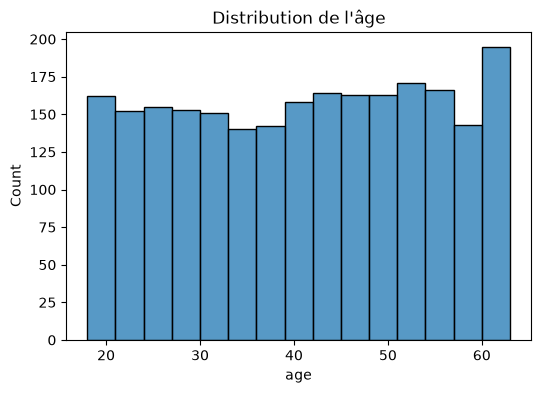

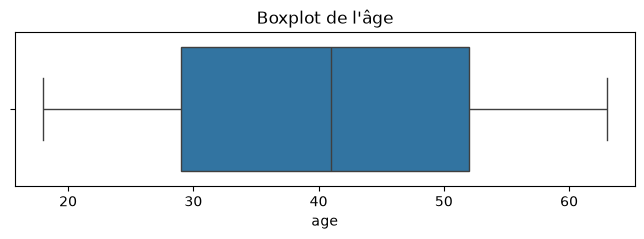

In [94]:
# Distribution de l'age
plt.figure(figsize=(6,4))
sns.histplot(df["age"], bins=15)
plt.title("Distribution de l'âge")
plt.show()

plt.figure(figsize=(8,2))
sns.boxplot(x=df["age"])
plt.title("Boxplot de l'âge")
plt.show()

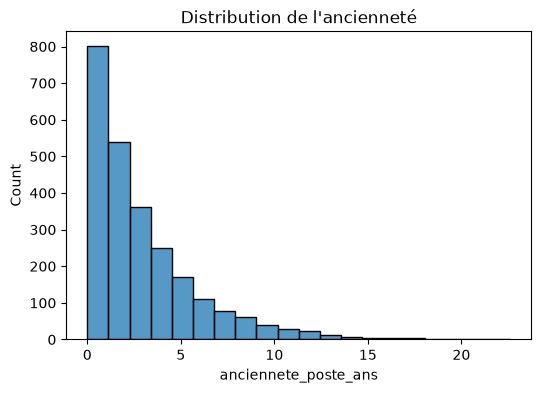

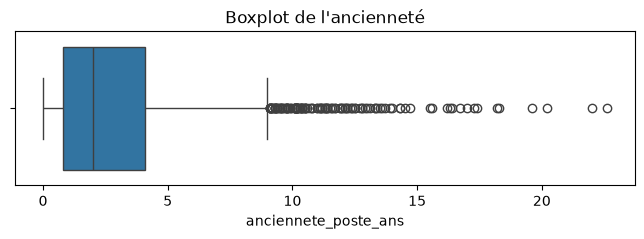

In [95]:
plt.figure(figsize=(6,4))
sns.histplot(df["anciennete_poste_ans"], bins=20)
plt.title("Distribution de l'ancienneté")
plt.show()

plt.figure(figsize=(8,2))
sns.boxplot(x=df["anciennete_poste_ans"])
plt.title("Boxplot de l'ancienneté")
plt.show()

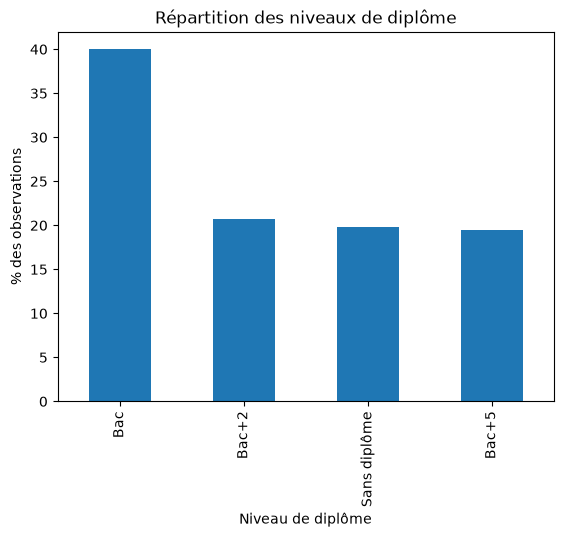

In [96]:
df["niveau_diplome"].value_counts(normalize=True).mul(100).sort_values(ascending=False).plot(kind="bar")

plt.title("Répartition des niveaux de diplôme")
plt.ylabel("% des observations")
plt.xlabel("Niveau de diplôme")
plt.show()

In [97]:
pd.DataFrame({"nb_observations": df["code_rome_vise"].value_counts()}).describe()

,nb_observations
count,50.000000
mean,50.000000
std,8.141604
min,30.000000
25%,45.000000
50%,48.500000
75%,54.750000
max,71.000000


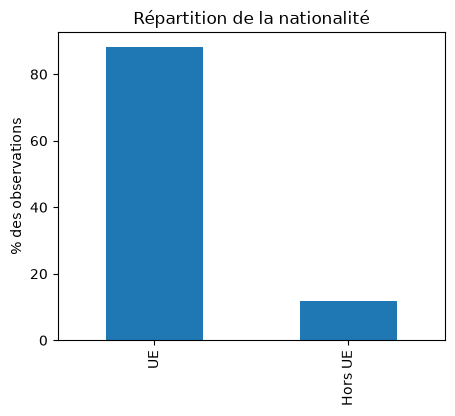

In [98]:
df["nationalite_hors_ue"].value_counts(normalize=True).sort_index().mul(100).rename(index={0: "UE", 1: "Hors UE"}).plot(kind="bar", figsize=(5,4))

plt.title("Répartition de la nationalité")
plt.ylabel("% des observations")
plt.xlabel("")
plt.show()

### Conclusion

- Comme attendu après analyse des valeurs moyenne et médiane, la variable `age` présente une répartition relativement homogène entre 18 et 63 ans. Le boxplot ne révèle aucune valeur aberrante selon la règle de l'écart interquartile (IQR), ce qui confirme la cohérence des données observées.
- La variable `anciennete_poste_ans` présente une distribution fortement asymétrique à droite. La majorité des usagers possède une ancienneté relativement faible, avec une médiane de 2 ans et un troisième quartile de 4,1 ans. Quelques individus présentent toutefois des anciennetés nettement plus élevées pouvant atteindre 22,6 ans.
Le boxplot identifie plusieurs observations comme atypiques selon le critère statistique de l'écart interquartile. Cependant, d'un point de vue métier ces valeurs sont cohérentes et seront donc conservées pour l'entrainement.
- L'analyse graphique de la variable `niveau_diplome` confirme que la catégorie « Bac » est la plus représentée avec 39,98 % des observations. On voit cependant que les trois autres niveaux de diplôme affichent des proportions proches (environ 20 % chacun), ce qui traduit une répartition globalement équilibrée. Cette observation confirme la valeur élevée obtenue pour l'entropie normalisée (0,961), indiquant une bonne diversité des modalités et l'absence de catégorie fortement sous-représentée.
- La variable `code_rome_vise` présente une cardinalité modérée de 50 modalités. L'analyse des effectifs montre une répartition particulièrement homogène entre les différents métiers visés. Chaque code ROME est représenté par au moins 30 observations et au plus 71, pour une moyenne de 50 observations. Aucune modalité rare ou sous-représentée n'a été identifiée, ce qui limite les risques liés à l'encodage des catégories et garantit une bonne représentativité des différents métiers dans l'apprentissage des modèles.
- La variable `nationalite_hors_ue` présente un déséquilibre marqué. Les usagers de nationalité hors Union Européenne représentent seulement 11,8 % de la population étudiée, contre 88,2 % pour les autres usagers. Cette sous-représentation peut limiter la capacité du modèle à apprendre correctement les caractéristiques de ce sous-groupe et conduire à des performances différentes selon les catégories de population. Une analyse des performances par sous-groupe ainsi que des indicateurs d'équité seront donc nécessaires afin de vérifier l'absence de biais discriminatoires.

### 3.3.1 Regroupement de la variable code_insee_commune

In [99]:
# Regroupement des codes INSEE par département
df["code_departement"] = df["code_insee_commune"].str[:2]

# Calcul de la répartition
vc = df["code_departement"].value_counts()

nb_modalites = vc.shape[0]
categorie_majoritaire = vc.index[0]
pct_majoritaire = 100 * vc.iloc[0] / vc.sum()

pct_moyen_theorique = 100 / nb_modalites
ratio_concentration = pct_majoritaire / pct_moyen_theorique

p = vc / vc.sum()
entropie_normalisee = entropy(p) / np.log(nb_modalites)

print(f"Nb modalités : {nb_modalites}")
print(f"Catégorie majoritaire : {categorie_majoritaire}")
print(f"% catégorie majoritaire : {pct_majoritaire:.2f}")
print(f"% moyen théorique : {pct_moyen_theorique:.2f}")
print(f"Ratio concentration : {ratio_concentration:.2f}")
print(f"Entropie normalisée : {entropie_normalisee:.3f}")


Nb modalités : 96
Catégorie majoritaire : 21
% catégorie majoritaire : 2.68
% moyen théorique : 1.04
Ratio concentration : 2.57
Entropie normalisée : 0.967


In [100]:
# Analyse d'impact de la variable agrégé `code_departement`

# Effectifs par département
effectifs = df["code_departement"].value_counts()

# On ne garde que les départements ayant un effectif suffisant pour une estimation plus fiable
deps_ok = effectifs[effectifs >= 20].index

ct = pd.crosstab(df.loc[df["code_departement"].isin(deps_ok), "code_departement"],
                 df.loc[df["code_departement"].isin(deps_ok), "classe_retour_emploi"],
                 normalize="index")

In [101]:
# Tri pour obtenir les départements ou la classe 2 est la plus fréquente
ct.sort_values(2, ascending=False).head(5)

classe_retour_emploi,0,1,2
code_departement,,,
02,0.186441,0.423729,0.389831
17,0.250000,0.437500,0.312500
64,0.250000,0.450000,0.300000
69,0.272727,0.454545,0.272727
88,0.315789,0.421053,0.263158


In [102]:
# Tri pour obtenir les départements ou la classe 2 est la moins fréquente
ct.sort_values(2, ascending=True).head(5)

classe_retour_emploi,0,1,2
code_departement,,,
29,0.424242,0.545455,0.030303
50,0.534884,0.418605,0.046512
07,0.523810,0.428571,0.047619
08,0.580645,0.354839,0.064516
65,0.365854,0.560976,0.073171


### Conclusion

- Le regroupement de la variable `code_insee_commune` permet de conserver l'information géographique tout en réduisant fortement la cardinalité (2407 communes -> 96 départements). La variable reste relativement dispersée, le département le plus représenté ayant 2.68% des individus soit ~67 personnes.
- Le regroupement réduit également le risque de réidentification des individus
- Après exclusion des départements disposant d'un effectif insuffisant, la proportion de la classe 2 varie d'environ 3 % à 39 % selon le département considéré, contre une moyenne globale de 18 %. Ces écarts suggèrent que l'information géographique pourrait être corrélée à la cible et présenter un intérêt prédictif.

### 3.3.2 Analyse de la feature `synthese_entretien`

<Axes: xlabel='classe_retour_emploi', ylabel='synthese_entretien'>

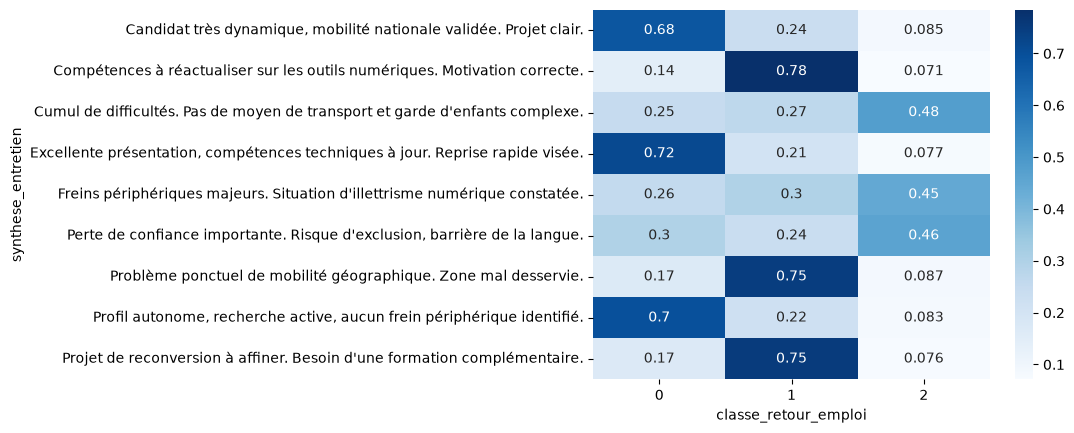

In [103]:
ct = pd.crosstab(df["synthese_entretien"],
                 df["classe_retour_emploi"],
                 normalize="index")

sns.heatmap(ct, annot=True, cmap="Blues")

### Conclusion

- La variable `synthese_entretien` ne contient que 9 modalités distinctes. On voit que les formulations correspondent à des profils génériques et ne comportent pas d'informations directement identifiantes. Elles décrivent cependant des situations personnelles ou sociales (barrière de la langue, illétrisme numérique, garde d'enfants complexe) qui peuvent constituer des proxy indirects de caractéristiques protégées. Une attention particulière devra donc être portée à l'interprétation des modèles exploitant cette variable.
- Le traitement de cette variable en variable catégorielle est à étudier, même si son fonctionnement exact (liste prédéfinie ou saisie libre contrainte) mériterait une confirmation métier.
- Cette variable est fortement discriminante vis-à-vis de la cible : 
    - les labels Dynamique, AUtonome et Compétences à jour sont majoritairement associé à la classe 0, 
    - les labels Reconversion, Mobilité et "Remise à niveau" sont majoritairement associé à la classe 1
    - les labels "Cumul de difficultés", "Freins périphériques" et "Perte de confiance" sont majoritairement associés à la classe 2
- Les écarts sur la classe 2 entre les trois groupes sont très importants passant de plus de 45% pour certains groupes à moins de 10% pour d'autre
- La variable `synthese_entretien` semble contenir énormément d'informations 


### 3.4 Variable cible : équilibre des classes

In [104]:
display(df["classe_retour_emploi"]
            .value_counts(normalize=True)
            .sort_index()
            .mul(100)
            .round(2))

classe_retour_emploi
0    37.44
1    44.48
2    18.08
Name: proportion, dtype: float64

### Conclusion 

Variable cible :
- La variable cible présente un léger déséquilibre. Cependant la classe minoritaire (2 : risque de longue durée) garde suffisamment d'échantillons (>450) pour l'entrainement. Le déséquilibre devra être pris en compte dans les métriques pour l'analyse des performances du modèle en utilisant le F1-score macro et les matrices de confusion et pas uniquement l'accuracy.

### 3.5 Corrélations & relations entre variables

#### 3.5.1 Variables numériques

In [105]:
num_cols = ["age", "anciennete_poste_ans"]

In [106]:
# Correlation ente les variables numériques
corr = df[num_cols].corr()

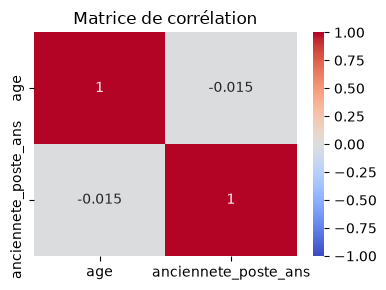

In [107]:
# Display 
plt.figure(figsize=(4,3))
sns.heatmap(corr,
            annot=True,
            cmap="coolwarm",
            vmin=-1,
            vmax=1)

plt.title("Matrice de corrélation")
plt.tight_layout()
plt.show()

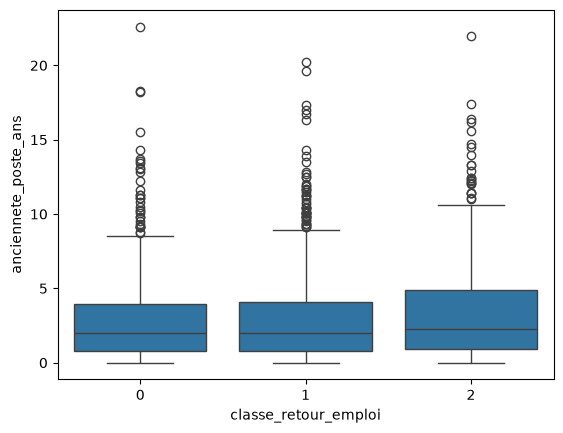

In [108]:
# Correlation de l'ancienneté à la cible
# L'age sera traité à part
sns.boxplot(data=df,
            x="classe_retour_emploi",
            y="anciennete_poste_ans")

plt.show()

#### 3.5.2 Variables catégorielles

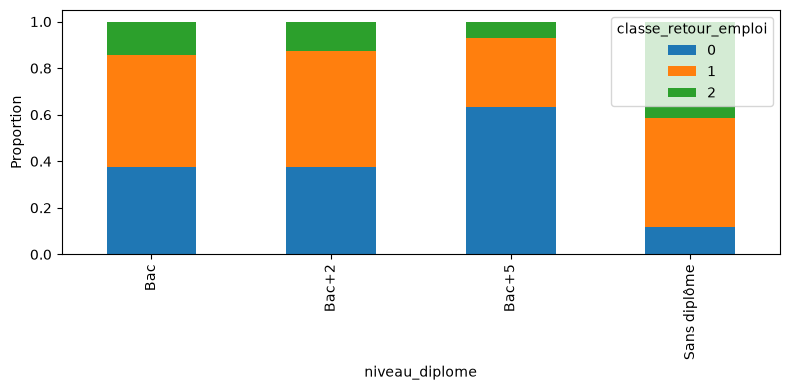

In [109]:
# Relations entre la variable classe_retour_emploi et la cible
ct = pd.crosstab(df["niveau_diplome"],
                 df["classe_retour_emploi"],
                 normalize="index")

ct.plot(kind="bar",
        stacked=True,
        figsize=(8,4))

plt.ylabel("Proportion")
plt.tight_layout()
plt.show()

In [110]:
# Relations entre la variable code_rome_vise et la cible
ct_rome = pd.crosstab(df["code_rome_vise"],
                      df["classe_retour_emploi"],
                      normalize="index")

ct_rome.sort_values(2, ascending=False).head(5)

classe_retour_emploi,0,1,2
code_rome_vise,,,
M1602,0.163934,0.442623,0.393443
M1607,0.146341,0.463415,0.390244
K1601,0.214286,0.428571,0.357143
M1501,0.244444,0.466667,0.288889
K2106,0.446809,0.276596,0.276596


In [111]:
ct_rome.sort_values(2, ascending=True).head(5)

classe_retour_emploi,0,1,2
code_rome_vise,,,
J1301,0.708333,0.270833,0.020833
M1805,0.500000,0.462963,0.037037
H1504,0.326531,0.632653,0.040816
K1201,0.500000,0.437500,0.062500
M1802,0.557692,0.365385,0.076923


### Conclusion

- Il n'existe pas de relation linéaire significative entre l'âge et l'ancienneté du poste (correlation de -0.015), les individus les plus âgés ne présentent pas systématiquement une ancienneté plus élevée.
- La variable `anciennete_poste_ans` semble également associée à la variable cible mais de manière moins marquée. Les individus ayant une durée retour à l'emploi de classe 2 ont une ancienneté légèrement supérieure à celle des 2 autres classes.
- L'histogramme de corrélation entre la variable `niveau_diplome` et la variable cible montre une relation entre ces 2 variables et montre que cette variable pourrait contribuer significativement aux performances du modèle. 
    - Les individus disposant d'un diplôme Bac+5 sont majoritairement associés à la classe 0 (environ 63 %) et très rarement à la classe 2 (environ 7 %)
    - À l'inverse, les usagers sans diplôme présentent une proportion nettement plus importante de classe 2 et une proportion réduite de classe 0
    - Les catégories Bac et Bac+2 présentent des répartitions intermédiaires relativement proches.
- On constate également que les catégorie de cette variable possèdent un ordre naturel et pourrait être encodée de manière ordinale (Sans diplôme < Bac < Bac+2 < Bac+5)
- L'analyse decorrélation de la variable `code_rome_vise` avec la cible montre des disparités importantes dans la proportion de classe 2 suivant les types de métiers visés. La répartition des ratios entre 2.08% et 39.3% pour la classe 2, suggère que la variable `code_rome_vise` contient de l'information prédictive

### 3.6 Analyse des biais & variables sensibles

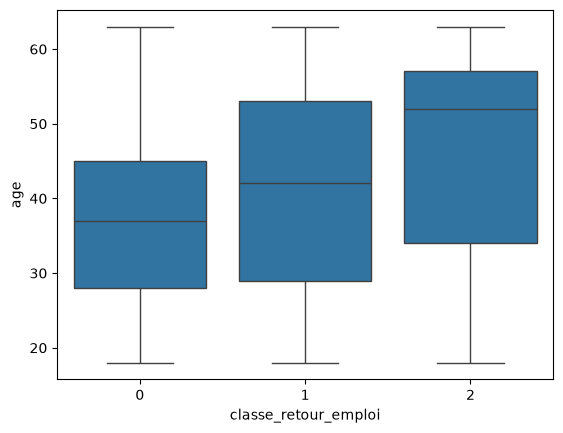

In [112]:
# Correlation ente l'age et la variable cible
sns.boxplot(data=df,
            x="classe_retour_emploi",
            y="age")

plt.show()

In [113]:
# On définit comme outcome favorable un retour à l'emploi rapide ou moyen
df["outcome_favorable"] = df["classe_retour_emploi"].isin([0,1]).astype(int)

# On crée des bins pour la variable age pour affiner les résultats
df["tranche_age"] = pd.cut(df["age"], 
                           bins=[18, 30, 40, 50, 60, 70], 
                           labels=["18-29", "30-39", "40-49", "50-59", "60+"], 
                           right=False)

pd.crosstab(df["tranche_age"], df["classe_retour_emploi"], normalize="index").mul(100).round(2)

classe_retour_emploi,0,1,2
tranche_age,,,
18-29,41.64,44.21,14.15
30-39,52.58,38.97,8.45
40-49,49.62,41.70,8.68
50-59,15.93,50.73,33.33
60+,10.26,50.77,38.97


In [114]:
# DI de la variable age
taux_ref = (df.loc[df["tranche_age"] == "30-39", "outcome_favorable"].mean())

di_age = (df.groupby("tranche_age")["outcome_favorable"].mean() / taux_ref).round(3)

display(di_age)

tranche_age
18-29    0.938
30-39    1.000
40-49    0.998
50-59    0.728
60+      0.667
Name: outcome_favorable, dtype: float64

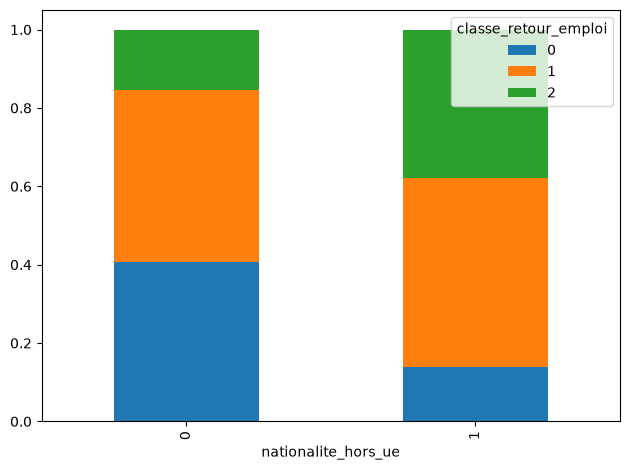

In [115]:
# Correlation ente l'origine et la variable cible
ct = pd.crosstab(df["nationalite_hors_ue"],
                 df["classe_retour_emploi"],
                 normalize="index")

ct.plot(kind="bar", stacked=True)
plt.tight_layout()

In [116]:
# DI de la variable `nationalite_hors_ue`
taux_reference = df[df["nationalite_hors_ue"] == 0]["outcome_favorable"].mean()
taux_protege = df[df["nationalite_hors_ue"] == 1]["outcome_favorable"].mean()

di = taux_protege / taux_reference

print(f"Disparate Impact nationalite_hors_ue : {di:.3f}")

Disparate Impact nationalite_hors_ue : 0.733


### Conclusion

- Le boxplot entre la variable `age` et la cible montre une **augmentation de la médiane** pour les classes de retour à l'emploi 1 et 2. Le recouvrement entre les distribution suggère que l'âge ne permet pas à lui seul d'expliquer la variable cible mais qu'il constitue un facteur important. Étant le caractère sensible de la variable, son utilisation devra faire l'objet d'une vigilance particulière lors de la modélisation.
- L'analyse par **tranche d'âges** on voit que la classe 2, retour rapide à l'amploi, diminue fortement après 50 ans au profit de la classe 2, risque de longue durée.
- Les **indicateurs de disparate impacts**  calculés sur l'outcome favorable mettent en évidence des disparités modérées liées à l'âge et à la nationalité. Les groupes **50-59 ans**, **60 ans et plus** ainsi que la populati;on **hors UE** présentent des valeurs inférieures au seuil d'alerte de **0,8**
- Ces résultats montrent que les données d'entraînement contiennent des déséquilibres susceptibles d'être reproduits ou amplifiés et justifient la comparaison de scénarios avec et sans variables sensibles, ainsi qu'une évaluation des performances et de l'équité par sous-groupes.

### DI croisé age / nationalité

In [117]:
df["groupe_age_nat"] = (df["tranche_age"].astype(str) + "_" + df["nationalite_hors_ue"].astype(str))

resultats = (df.groupby("groupe_age_nat").agg(effectif=("outcome_favorable", "size"), taux_favorable=("outcome_favorable", "mean")))

ref = resultats["taux_favorable"].max()

resultats["DI"] = resultats["taux_favorable"] / ref

resultats.sort_values("DI")

,effectif,taux_favorable,DI
groupe_age_nat,,,
60+_1,25,0.080000,0.085854
50-59_1,58,0.241379,0.259041
60+_0,170,0.688235,0.738594
50-59_0,488,0.717213,0.769692
30-39_1,45,0.755556,0.810840
18-29_1,93,0.774194,0.830842
18-29_0,529,0.873346,0.937249
40-49_1,61,0.901639,0.967613
40-49_0,469,0.914712,0.981642


## Conclusion

L'analyse croisée de l'âge et de la nationalité met en évidence un phénomène d'intersectionnalité : La combinaison "âge élevé" et "nationalité hors UE" entraîne une diminution beaucoup plus forte du taux de retour à l'emploi favorable que chacun de ces facteurs pris individuellement. C'est le cas pour les groupes **"50-59 ans hors UE"** (DI = 0,259 ; effectif = 58) et **"60 ans et plus hors UE"** (DI = 0,086 ; effectif = 25)

Ces résultats suggèrent l'existence de disparités cumulées dans les données, susceptibles d'être reproduites ou amplifiées par un modèle entraîné sur ce jeu. Ils doivent toutefois être interprétés avec prudence en raison des effectifs réduits de certains sous-groupes, en particulier pour les usagers de **60 ans et plus hors UE**.

### 3.7 📝 Synthèse EDA

*[Top 5 enseignements de l'EDA. Hypothèses de travail pour la modélisation. Risques de biais identifiés. **Révision éventuelle des cibles 1.4** à la lumière de la donnée.]*

1. **La qualité globale des données est satisfaisante.**  
   Le jeu de données ne présente ni doublons métier évidents, ni manquants implicites, ni valeurs aberrantes bloquantes sur le plan métier. Les quelques valeurs manquantes observées restent limitées.

2. **Les variables numériques sont cohérentes, mais l'ancienneté est asymétrique.**  
   L'âge présente une distribution relativement équilibrée, tandis que `anciennete_poste_ans` est fortement asymétrique à droite, avec quelques valeurs élevées mais plausibles.
   **Implication pour l'entraînement :** ces observations doivent être conservées ; il faudra privilégier un prétraitement robuste et comparer des modèles capables de gérer des distributions non gaussiennes.

3. **Certaines variables semblent très informatives pour la cible.**  
   `niveau_diplome`, `anciennete_poste_ans`, `code_rome_vise`, la géographie agrégée et surtout `synthese_entretien` montrent des différences marquées selon les classes de retour à l'emploi.
   **Implication pour l'entraînement :** ces variables constituent des candidates importantes pour la prédiction et devront être conservées dans les scénarios de base. Une attention particulière devra être portée à la contribution réelle de `synthese_entretien`, qui semble très discriminante.

4. **La variable géographique brute est trop fine pour être utilisée telle quelle.**  
   `code_insee_commune` présente une très forte cardinalité, avec une information très fragmentée. Le regroupement au niveau département réduit fortement cette complexité tout en conservant un signal potentiellement utile.
   **Implication pour l'entraînement :** il est préférable d'utiliser une variable géographique agrégée (`departement`) plutôt que la commune brute, afin de limiter la dilution des features et le risque de surapprentissage.

5. **La variable cible est légèrement déséquilibrée, sans être inutilisable.**  
   La classe 2 est minoritaire mais reste suffisamment représentée pour être apprise correctement.
   **Implication pour l'entraînement :** l'évaluation ne devra pas reposer sur l'accuracy seule. Le **F1-score macro**, les **matrices de confusion** et l'analyse des erreurs sur la classe 2 seront prioritaires.

6. **Des risques de biais sont déjà visibles dans les données.**  
   L'âge et la nationalité hors UE apparaissent associés à des différences d'outcome favorable, avec un signal renforcé dans l'analyse croisée âge / nationalité. Ces disparités existent avant même la modélisation.
   **Implication pour l'entraînement :** il faudra comparer plusieurs scénarios avec et sans variables sensibles, mesurer les performances par sous-groupes et suivre des indicateurs d'équité pour vérifier si le modèle reproduit ou amplifie ces déséquilibres.

### Hypothèses de travail pour la modélisation

- construire au moins un scénario **baseline** avec l'ensemble des variables utiles. On exclut la variable `usager_id` qui est un identifiant de traçabilité ;
- utiliser une **géographie agrégée** plutôt que `code_insee_commune` ;
- tester `synthese_entretien` soit comme **variable catégorielle**, soit comme **texte vectorisé**, puis arbitrer empiriquement ;
- privilégier des modèles robustes sur données tabulaires hétérogènes ;
- tester un scénario **sans variables sensibles** (`age`, `nationalite_hors_ue`) ;
- évaluer systématiquement le compromis **performance / robustesse / équité**.

### Révision des critères de succès

Au vu de l'EDA, les critères définis en section 1.4 restent pertinents. Ils doivent néanmoins être complétés par deux points de vigilance opérationnels :  
- une attention spécifique aux erreurs sur la **classe 2**, qui reste la classe métier la plus critique ;  
- une analyse explicite de l'**équité par sous-groupes**, en particulier selon l'âge et la nationalité.

---
## 4. Préparation des données

### 4.1 Chargement des données

In [141]:
# UTILS
# =====
ID_COLUMN = "usager_id"
TARGET_COLUMN = "classe_retour_emploi"
TEXT_COLUMN = "synthese_entretien"
RAW_REQUIRED_COLUMNS = [ID_COLUMN,
                        "age",
                        "niveau_diplome",
                        "anciennete_poste_ans",
                        "code_rome_vise",
                        "code_insee_commune",
                        "est_allocataire",
                        "nationalite_hors_ue",
                        TEXT_COLUMN,
                        TARGET_COLUMN]

DERIVED_COLUMNS = ["departement"]

def extract_departement(code_insee: object) -> str:
    """Extrait le département à partir d'un code INSEE commune.

    Gère notamment :
    - les départements métropolitains ;
    - la Corse avec 2A et 2B ;
    - les départements et régions d'outre-mer.
    """
    if pd.isna(code_insee):
        return "INCONNU"

    code = str(code_insee).strip().upper()

    # Nettoyage du cas où pandas a lu le code comme un float : 63000.0
    if code.endswith(".0"):
        code = code[:-2]

    # On remet les codes métropolitains sur cinq caractères
    if code.isdigit() and len(code) < 5:
        code = code.zfill(5)

    if code.startswith(("971", "972", "973", "974", "975", "976")):
        return code[:3]

    if code.startswith(("2A", "2B")):
        return code[:2]

    if len(code) >= 2:
        return code[:2]

    return "INCONNU"

# def extract_domaine_rome(code_rome: object) -> str:
#     """Extrait le domaine principal du code ROME.

#     Exemple :
#         M1805 -> M
#         N4103 -> N
#     """
#     if pd.isna(code_rome):
#         return "INCONNU"

#     code = str(code_rome).strip().upper()

#     if not code:
#         return "INCONNU"

#     return code[0]

In [142]:
def load_dataset(path: str | Path) -> pd.DataFrame:
    """Charge les données, crée les caractéristiques et retourne X et y."""
    path = Path(path)

    df = pd.read_csv(path,
                     sep=",",
                     dtype={"code_insee_commune": "string",
                            "code_rome_vise": "string"})

    missing_columns = [column for column in RAW_REQUIRED_COLUMNS if column not in df.columns]
    if missing_columns:
        raise KeyError(f"Colonnes absentes du fichier : {missing_columns}")

    # Feature engineering
    df["departement"] = (df["code_insee_commune"].apply(extract_departement))
    # df["domaine_rome"] = (df["code_rome_vise"].apply(extract_domaine_rome))

    if df[TARGET_COLUMN].isna().any():
        raise ValueError("La variable cible contient des valeurs manquantes.")

    return df

### 4.2 Split des données

In [143]:
df = load_dataset(Path(DATASET_SOURCE) / DATASET_NAME)
df_train, df_test = train_test_split(df,
                                     test_size=0.20,
                                     stratify=df[TARGET_COLUMN],
                                     random_state=RANDOM_STATE)

### 4.3 Définition des Scénarios

In [247]:
scenarios = {1: "S1 - Baseline avec toutes les variables",
             2: "S2 - Sans variables sensibles",
             3: "S3 - Texte seul",
             4: "S4 - Tabulaire seul",
             5: "S5 - Baseline avec toutes les variables + Texte variable catégorielle",
             6: "S6 - Baseline avec toutes les variables + niveau_diplome ordinal",
             7: "S7 - Baseline sans âge"}

In [251]:
from typing import Tuple, List, Optional

def get_features_by_scenario(num_scenario: int) -> Tuple[List[str],      # numeric_features
                                                         List[str],      # categorical_features
                                                         List[str],      # ordinal_features
                                                         Optional[str],  # text_feature
                                                         str,            # target_column
                                                         List[str],      # excluded_features
                                                        ]:
    target_column = TARGET_COLUMN

    if num_scenario == 1:
        # baseline toutes les features
        numeric_features = ["age",
                            "anciennete_poste_ans"]
        categorical_features = ["niveau_diplome",
                                "est_allocataire",
                                "nationalite_hors_ue",
                                "departement",
                                "code_rome_vise"]
        ordinal_features = []
        text_feature = TEXT_COLUMN
        excluded_features = [ID_COLUMN,
                             "code_insee_commune"]

    elif num_scenario == 2:
        # Sans variables sensibles
        numeric_features = ["anciennete_poste_ans"]
        categorical_features = ["niveau_diplome",
                                "est_allocataire",
                                "departement",
                                "code_rome_vise"]
        ordinal_features = []
        text_feature = TEXT_COLUMN
        excluded_features = [ID_COLUMN,
                             "age",
                             "nationalite_hors_ue",
                             "code_insee_commune"]

    elif num_scenario == 3:
        # Texte seul
        numeric_features = []
        categorical_features = []
        ordinal_features = []
        text_feature = TEXT_COLUMN
        excluded_features = [ID_COLUMN,
                             "code_insee_commune",
                             "code_rome_vise",
                             "age",
                             "anciennete_poste_ans",
                             "niveau_diplome",
                             "est_allocataire",
                             "nationalite_hors_ue",
                             "departement"]

    elif num_scenario == 4:
        # Tabulaire seul
        numeric_features = ["age",
                            "anciennete_poste_ans"]
        categorical_features = ["niveau_diplome",
                                "est_allocataire",
                                "nationalite_hors_ue",
                                "departement",
                                "code_rome_vise"]
        ordinal_features = []
        text_feature = None
        excluded_features = [ID_COLUMN,
                             "code_insee_commune",
                             TEXT_COLUMN]
    elif num_scenario == 5:
            # Tabulaire seul
            numeric_features = ["age",
                                "anciennete_poste_ans"]
            categorical_features = ["niveau_diplome",
                                    "est_allocataire",
                                    "nationalite_hors_ue",
                                    "departement",
                                    "code_rome_vise",
                                    TEXT_COLUMN]
            ordinal_features = []
            text_feature = None
            excluded_features = [ID_COLUMN,
                                 "code_insee_commune"]
    elif num_scenario == 6:
            # variante baseline toutes les features + nioveau_diplome ordinal
            numeric_features = ["age",
                                "anciennete_poste_ans"]
            categorical_features = ["est_allocataire",
                                    "nationalite_hors_ue",
                                    "departement",
                                    "code_rome_vise"]
            ordinal_features = ["niveau_diplome"]
            text_feature = TEXT_COLUMN
            excluded_features = [ID_COLUMN,
                                    "code_insee_commune"]
    elif num_scenario == 7:
        # Baseline sans âge, mais nationalité conservée + texte catégoriel
        numeric_features = ["anciennete_poste_ans"]
        categorical_features = ["niveau_diplome",
                                "est_allocataire",
                                "nationalite_hors_ue",
                                "departement",
                                "code_rome_vise",
                                TEXT_COLUMN]
        ordinal_features = []
        text_feature = None
        excluded_features = [ID_COLUMN,
                             "age",
                             "code_insee_commune"]
    else:
        raise ValueError(f"Scénario inconnu : {num_scenario}")

    return (numeric_features,
            categorical_features,
            ordinal_features,
            text_feature,
            target_column,
            excluded_features)

In [234]:
def prepare_dataset_for_scenario(df: pd.DataFrame,
                                 numeric_features: list[str],
                                 categorical_features: list[str],
                                 ordinal_features: list[str],
                                 text_feature: str | None,
                                 target_column: str = TARGET_COLUMN,
                                 drop_empty_text: bool = True) -> tuple[pd.DataFrame, pd.Series]:
    """Sélectionne les variables utiles pour un scénario donné."""
    df_prepared = df.copy()

    selected_features = numeric_features + categorical_features + ordinal_features

    # Remplacer un texte manquant par une chaine vide
    if text_feature is not None:
        df_prepared[text_feature] = (df_prepared[text_feature].fillna("").astype(str))
        selected_features.append(text_feature)

    X = df_prepared[selected_features].copy()
    y = df_prepared[target_column].copy()

    return X, y

### 4.4 Pipeline

In [235]:
def build_preprocessor(numeric_features: list[str],
                       categorical_features: list[str],
                       ordinal_features: list[str],
                       text_feature: str | None = None) -> ColumnTransformer:
    """Construit un préprocesseur adapté au scénario."""

    transformers = []

    if numeric_features:
        numeric_pipeline = Pipeline(steps=[("imputer", SimpleImputer(strategy="median")),
                                           ("scaler", StandardScaler())])
        transformers.append(("num", numeric_pipeline, numeric_features))

    if categorical_features:
        categorical_pipeline = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")),
                                               ("onehot", OneHotEncoder(handle_unknown="ignore"))])
        transformers.append(("cat", categorical_pipeline, categorical_features))

    if ordinal_features:
        ordinal_pipeline = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")),
                                           ("ordinal",OrdinalEncoder(categories=[["Sans diplôme", "Bac", "Bac+2", "Bac+5"]],
                                                                     handle_unknown="use_encoded_value",
                                                                     unknown_value=-1)),               
                                           ("scaler", StandardScaler())])
        transformers.append(("ordinal", ordinal_pipeline, ordinal_features))

    if text_feature is not None:
        text_pipeline = TfidfVectorizer(lowercase=True,
                                        strip_accents="unicode",
                                        max_features=2000,
                                        min_df=3,
                                        max_df=0.95,
                                        ngram_range=(1, 2),
                                        stop_words=list(STOP_WORDS),
                                        sublinear_tf=True)
        transformers.append(("text", text_pipeline, text_feature))

    if not transformers:
        raise ValueError("Aucune feature fournie pour construire le préprocesseur.")

    return ColumnTransformer(transformers=transformers, remainder="drop")

In [236]:
### 4.5 Assertions : vérification des dataset de test et de validation

In [237]:
assert not df.empty, "Le dataset est vide."
assert df[TARGET_COLUMN].notna().all(), "La cible contient des valeurs manquantes."

assert len(df_train) + len(df_test) == len(df), "Split incomplet."
assert set(df_train.index).isdisjoint(df_test.index), (
    "Chevauchement détecté entre train et test."
)

assert set(df_train[TARGET_COLUMN].unique()).issubset({0, 1, 2}), (
    "Classes cibles inattendues dans le train."
)
assert set(df_test[TARGET_COLUMN].unique()).issubset({0, 1, 2}), (
    "Classes cibles inattendues dans le test."
)

classes_attendues = {0, 1, 2}
assert set(df_train[TARGET_COLUMN].unique()) == classes_attendues, (
    "Une ou plusieurs classes attendues sont absentes du train."
)
assert set(df_test[TARGET_COLUMN].unique()) == classes_attendues, (
    "Une ou plusieurs classes attendues sont absentes du test."
)

print("Dataset chargé et cible validée.")
print(f"Split train/test validé : "
      f"{df_train.shape[0]} lignes pour le train, "
      f"{df_test.shape[0]} lignes pour le test.")
print(f"Classes présentes dans les deux jeux : {sorted(classes_attendues)}.")

Dataset chargé et cible validée.
Split train/test validé : 2000 lignes pour le train, 500 lignes pour le test.
Classes présentes dans les deux jeux : [0, 1, 2].


In [241]:
# Vérifier que toutes les features sont prises encompte dans la répartition par scénario
for num_scenario, nom_scenario in scenarios.items():
    (numeric_features,
     categorical_features,
     ordinal_features,
     text_feature,
     target_column,
     excluded_features) = get_features_by_scenario(num_scenario)

    X_train_scenario, y_train_scenario = prepare_dataset_for_scenario(
                                                df=df_train,
                                                numeric_features=numeric_features,
                                                categorical_features=categorical_features,
                                                ordinal_features=ordinal_features,
                                                text_feature=text_feature,
                                                target_column=target_column)

    X_test_scenario, y_test_scenario = prepare_dataset_for_scenario(
                                                df=df_test,
                                                numeric_features=numeric_features,
                                                categorical_features=categorical_features,
                                                ordinal_features=ordinal_features,
                                                text_feature=text_feature,
                                                target_column=target_column)

    features_attendues = (numeric_features
                          + categorical_features
                          + ordinal_features
                          + ([text_feature] if text_feature is not None else []))

    assert list(X_train_scenario.columns) == features_attendues, (
        f"{nom_scenario} : features incorrectes dans X_train."
    )

    assert list(X_test_scenario.columns) == features_attendues, (
        f"{nom_scenario} : features incorrectes dans X_test."
    )

    assert X_train_scenario.shape[0] == y_train_scenario.shape[0], (
        f"{nom_scenario} : nombre de lignes différent entre X_train et y_train."
    )

    assert X_test_scenario.shape[0] == y_test_scenario.shape[0], (
        f"{nom_scenario} : nombre de lignes différent entre X_test et y_test."
    )

    print(f"{nom_scenario} : sélection des features validée.")

print("Toutes les assertions par scénario sont validées.")

S1 - Baseline avec toutes les variables : sélection des features validée.
S2 - Sans variables sensibles : sélection des features validée.
S3 - Texte seul : sélection des features validée.
S4 - Tabulaire seul : sélection des features validée.
S5 - Baseline avec toutes les variables + Texte variable catégorielle : sélection des features validée.
S6 - Baseline avec toutes les variables + niveau_diplome ordinal : sélection des features validée.
Toutes les assertions par scénario sont validées.


### 4.4 📝 Synthèse préparation

L’objectif de cette étape est de construire un processus de préparation reproductible et de garantir que les résultats des modèles pourront être comparés de manière fiable. 

La préparation commence par le contrôle des données attendues et par la création de la variable departement, retenue afin de réduire la très forte granularité géographique du code commune tout en conservant un niveau de contexte utile.

Les données sont séparées une seule fois en un jeu d’entraînement et un jeu de test, selon une répartition stratifiée de 80 % / 20 %. Cette séparation est réalisée avant tout apprentissage ou transformation statistique, afin d'éviter toute fuite dans les données. Le jeu d’entraînement sert aux validations croisées et aux choix de modèles ; le jeu de test est réservé à l’évaluation finale.

Les traitements sont centralisés dans un pipeline afin que les mêmes règles soient appliquées de manière cohérente à chaque scénario et à chaque fold de validation. L’objectif est d’éviter les fuites de données et de permettre une comparaison équitable des modèles et des scénarios. Les prétraitements choisis sont l'imputation et la standardisation pour les variables numériques, l'imputation et l'encodage pour les variables catégorielles, la vectorisation TF-IDF de la synthèse d’entretien lorsque le texte est inclus.

Enfin, plusieurs scénarios sont définis pour mesurer l’apport respectif des données tabulaires et textuelles, ainsi que le compromis entre performance et équité induit par le retrait des variables sensibles.

---
## 5. Modélisation & entraînement

### 5.0 Synthèse des familles de modèles

Le problème étudié est une classification multiclasse sur un jeu de données de taille modérée, composé majoritairement de variables tabulaires et d'une synthèse d'entretien limitée à neuf profils récurrents. 

Les modèles de machine learning classique sont donc particulièrement adpatés. Ils peuvent gérer des variables numériques et catégorielles, sont compatibles avec un encodage one-hot et sont rapides à entraîner sur 2 500 observations. Ils sont suffisamment explicables pour un usage d'aide à la décision. La régression logistique, Random Forest, XGBoost et LightGBM seront comparés dans le cadre d'une validation croisée stratifiée.

Les approches de deep learning ne sont pas retenues. Le volume disponible est limité pour entraîner un réseau de neurones de manière robuste. De plus aucun gains attendus ne justifient le surcoût d'entraînement, et la moindre explicabilité de ces modèles est également un frein pour le contexte métier.

Les petits modèles de langage, les grands modèles de langage et les architectures RAG ou agentiques ne sont pas retenus. La synthèse d'entretien ne constitue pas un texte libre suffisamment riche ni un corpus documentaire nécessitant de la génération, de la recherche d'information ou l'utilisation d'outils. Les neuf formulations observées peuvent être modélisées plus simplement comme une variable catégorielle, ce qui est plus explicable, plus léger et plus adapté à l'objectif de prédiction.

| Famille | Adapté au use case | Coût (train + inférence) | Explicabilité | Dépendance fournisseur | Décision |
|---|---|---|---|---|---|
| ML classique (Random Forest, Régression Logistique, XGBoost, LightGBM) | Oui : classification multiclasse sur 2 500 observations principalement tabulaires, avec variables numériques et catégorielles | Faible à moyen ; entraînement et inférence rapides sur CPU | Élevée à moyenne | Aucune | **Retenue** |
| Deep Learning | Peu adapté : volume de données limité et absence d'images ou de texte libre riche | Élevé ; entraînement plus coûteux, nécessitant une GPU | Faible | Aucune, hors fine tuning modèle propriétaire | **Écartée** |
| SLM local (Ollama, modèles ≤ 7B) | Peu adapté : pas de besoin de génération, et la synthèse comporte seulement 9 profils récurrents | Moyen à élevé ; ressources matérielles nécessaires à l'inférence | Faible à moyenne | Aucune si hébergé localement | **Écartée** |
| LLM API + RAG | Non adapté : pas de question ouverte ni de corpus documentaire à interroger | Élevé ; coût par token, latence et maintenance de la chaîne RAG | Faible | Forte : fournisseur API et modèle choisi | **Écartée** |

### 5.1 Modèles candidats

| Modèle | Famille | Intérêt | Coût (entraînement / inférence) | Explicabilité |
|---|---|---|---|---|
| DummyClassifier | Baseline naïve | Fournit un niveau de référence minimal, afin de vérifier que que les autres modèles apprennent réellement un signal utile. | Très faible / très faible | Élevée |
| Régression logistique | Linéaire | Modèle de référence simple, rapide et interprétable. Compatible avec les variables numériques standardisées, les variables catégorielles encodées et les représentations TF-IDF creuses. | Faible / faible | Élevée |
| Random Forest | Ensemble d'arbres par bagging | Adapté aux données tabulaires hétérogènes et aux relations non linéaires. Robuste au bruit et aux interactions entre variables, avec un réglage initial généralement limité. | Moyen / faible | Moyenne |
| XGBoost | Gradient boosting | Modèle de boosting reconnu pour sa capacité à modéliser des relations complexes et des interactions sur des données tabulaires. Constitue un candidat pertinent lorsque la performance prédictive est prioritaire. | Élevé / faible | Moyenne |
| LightGBM | Gradient boosting | Variante de gradient efficace sur CPU, adapté aux données tabulaires de taille modérée et capable de capturer des relations non linéaires et des interactions entre variables. | Moyen / faible | Moyenne |

### 5.2 Exploration des modèles candidats sur les scénarios définis

In [242]:
models = {"dummy": DummyClassifier(strategy="most_frequent"),
          "logistic_regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
          "random_forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE),
          "xgboost":XGBClassifier(objective="multi:softprob",
                                  num_class=3,
                                  random_state=RANDOM_STATE,
                                  eval_metric="mlogloss"),
          "lightgbm": LGBMClassifier(objective="multiclass",
                                     num_class=3,
                                     random_state=RANDOM_STATE,
                                     verbose=-1)}

In [243]:
# Ajout d'un critère sur le taux d'erreur critique lors du fit
# C'est l'erreur métier la plus grave
def taux_erreur_critique(y_true, y_pred) -> float:
    """Part des classe 2 réelles prédites à tort en classe 0."""
    matrice = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

    nb_reels_classe_2 = matrice[2].sum()

    if nb_reels_classe_2 == 0:
        return 0.0

    return matrice[2, 0] / nb_reels_classe_2

In [244]:
# Lors de la première passe le recall de la classe 2 était de 0.52
# Ajout d'un critère d'erreur sur l'erreur le recall classe 2
def recall_classe_2(y_true, y_pred) -> float:
    """Part des vraies classes 2 correctement prédites."""
    matrice = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

    nb_reels_classe_2 = matrice[2].sum()

    if nb_reels_classe_2 == 0:
        return 0.0

    return matrice[2, 2] / nb_reels_classe_2

In [245]:
# Définition des critères de score
# scoring = {"f1_macro": "f1_macro",
#            "taux_erreur_critique": make_scorer(taux_erreur_critique,
#                                                greater_is_better=False)
#           }

scoring = {"f1_macro": "f1_macro",
           "taux_erreur_critique_2_vers_0": make_scorer(taux_erreur_critique,
                                                        greater_is_better=False),
           "recall_classe_2": make_scorer(recall_classe_2),
          }

In [252]:
# Cross Validation 5 folds préservant la répartition
cv = StratifiedKFold(n_splits=5,
                     shuffle=True,
                     random_state=RANDOM_STATE)



resultats_par_scenario = {}
for num_scenario, nom_scenario in scenarios.items():
      print(f"\n{'=' * 70}")
      print(nom_scenario)
      print(f"{'=' * 70}")

      (numeric_features, 
      categorical_features,
      ordinal_features,
      text_feature, 
      target_column, 
      excluded_features) = get_features_by_scenario(num_scenario)

      X_train, y_train = prepare_dataset_for_scenario(df=df_train,
                                                      numeric_features=numeric_features,
                                                      categorical_features=categorical_features,
                                                      ordinal_features=ordinal_features,
                                                      text_feature=text_feature,
                                                      target_column=target_column)
      
      preprocessor = build_preprocessor(numeric_features=numeric_features,
                                        ordinal_features=ordinal_features,
                                        categorical_features=categorical_features,
                                        text_feature=text_feature)
      
      resultats_scenario = []
      for nom_modele, model in models.items():
            # Construction du pipeline ML
            pipeline = Pipeline(steps=[("preprocessor", preprocessor),
                                    ("model", model)])
      
            scores = cross_validate(estimator=pipeline,
                                    X=X_train,
                                    y=y_train,
                                    cv=cv,
                                    scoring=scoring,
                                    return_train_score=False)

            scores_f1_folds = scores["test_f1_macro"]
            # taux_erreur_critique_folds = -scores["test_taux_erreur_critique"]
            taux_erreur_critique_folds = -scores["test_taux_erreur_critique_2_vers_0"]
            recall_classe_2_folds = scores["test_recall_classe_2"]

            resultats_scenario.append({"scénario": f"S{num_scenario}",
                                       "modèle": nom_modele,
                                       "fold_1": scores_f1_folds[0],
                                       "fold_2": scores_f1_folds[1],
                                       "fold_3": scores_f1_folds[2],
                                       "fold_4": scores_f1_folds[3],
                                       "fold_5": scores_f1_folds[4],
                                       "f1_macro_moyen": scores_f1_folds.mean(),
                                       "f1_macro_ecart_type": scores_f1_folds.std(),
                                       "taux_erreur_critique_moyen": taux_erreur_critique_folds.mean(),
                                       "taux_erreur_critique_max": taux_erreur_critique_folds.max(),
                                       "recall_classe_2_moyen": recall_classe_2_folds.mean(),
                                       "recall_classe_2_ecart_type": recall_classe_2_folds.std(),})

      tableau_scenario = (pd.DataFrame(resultats_scenario)
                        .sort_values("f1_macro_moyen", ascending=False)
                        .reset_index(drop=True))

      resultats_par_scenario[num_scenario] = tableau_scenario

      display(tableau_scenario.round(3))


S1 - Baseline avec toutes les variables


,scénario,modèle,fold_1,fold_2,fold_3,fold_4,fold_5,f1_macro_moyen,f1_macro_ecart_type,taux_erreur_critique_moyen,taux_erreur_critique_max,recall_classe_2_moyen,recall_classe_2_ecart_type
0,S1,lightgbm,0.686,0.674,0.724,0.691,0.719,0.699,0.020,0.113,0.164,0.597,0.050
1,S1,xgboost,0.699,0.677,0.724,0.677,0.714,0.698,0.019,0.108,0.151,0.553,0.062
2,S1,random_forest,0.639,0.680,0.689,0.672,0.678,0.672,0.017,0.160,0.222,0.625,0.038
3,S1,logistic_regression,0.668,0.661,0.696,0.657,0.674,0.671,0.014,0.135,0.181,0.688,0.030
4,S1,dummy,0.205,0.205,0.205,0.205,0.205,0.205,0.000,0.000,0.000,0.000,0.000



S2 - Sans variables sensibles


,scénario,modèle,fold_1,fold_2,fold_3,fold_4,fold_5,f1_macro_moyen,f1_macro_ecart_type,taux_erreur_critique_moyen,taux_erreur_critique_max,recall_classe_2_moyen,recall_classe_2_ecart_type
0,S2,logistic_regression,0.635,0.642,0.667,0.632,0.641,0.644,0.012,0.169,0.222,0.633,0.046
1,S2,random_forest,0.617,0.624,0.671,0.630,0.646,0.637,0.019,0.160,0.208,0.608,0.033
2,S2,lightgbm,0.633,0.615,0.650,0.593,0.628,0.624,0.019,0.205,0.264,0.467,0.019
3,S2,xgboost,0.607,0.601,0.652,0.586,0.616,0.612,0.022,0.188,0.250,0.450,0.043
4,S2,dummy,0.205,0.205,0.205,0.205,0.205,0.205,0.000,0.000,0.000,0.000,0.000



S3 - Texte seul


...

,scénario,modèle,fold_1,fold_2,fold_3,fold_4,fold_5,f1_macro_moyen,f1_macro_ecart_type,taux_erreur_critique_moyen,taux_erreur_critique_max,recall_classe_2_moyen,recall_classe_2_ecart_type
0,S5,xgboost,0.718,0.677,0.738,0.681,0.706,0.704,0.023,0.119,0.167,0.567,0.069
1,S5,lightgbm,0.691,0.693,0.735,0.687,0.712,0.704,0.018,0.108,0.153,0.602,0.053
2,S5,random_forest,0.662,0.708,0.734,0.700,0.712,0.703,0.024,0.130,0.167,0.647,0.039
3,S5,logistic_regression,0.652,0.666,0.694,0.653,0.664,0.666,0.015,0.133,0.181,0.685,0.038
4,S5,dummy,0.205,0.205,0.205,0.205,0.205,0.205,0.000,0.000,0.000,0.000,0.000



S6 - Baseline avec toutes les variables + niveau_diplome ordinal


,scénario,modèle,fold_1,fold_2,fold_3,fold_4,fold_5,f1_macro_moyen,f1_macro_ecart_type,taux_erreur_critique_moyen,taux_erreur_critique_max,recall_classe_2_moyen,recall_classe_2_ecart_type
0,S6,lightgbm,0.679,0.674,0.726,0.693,0.730,0.700,0.023,0.119,0.153,0.586,0.048
1,S6,xgboost,0.675,0.692,0.716,0.684,0.729,0.699,0.020,0.108,0.153,0.553,0.027
2,S6,random_forest,0.640,0.685,0.691,0.673,0.672,0.672,0.017,0.163,0.222,0.630,0.039
3,S6,logistic_regression,0.648,0.653,0.687,0.660,0.671,0.664,0.014,0.149,0.181,0.666,0.033
4,S6,dummy,0.205,0.205,0.205,0.205,0.205,0.205,0.000,0.000,0.000,0.000,0.000



S7 - Baseline sans âge


,scénario,modèle,fold_1,fold_2,fold_3,fold_4,fold_5,f1_macro_moyen,f1_macro_ecart_type,taux_erreur_critique_moyen,taux_erreur_critique_max,recall_classe_2_moyen,recall_classe_2_ecart_type
0,S7,logistic_regression,0.656,0.664,0.682,0.621,0.656,0.656,0.020,0.152,0.222,0.655,0.049
1,S7,random_forest,0.634,0.634,0.707,0.630,0.665,0.654,0.029,0.171,0.236,0.611,0.043
2,S7,xgboost,0.621,0.624,0.666,0.593,0.643,0.629,0.024,0.166,0.208,0.470,0.030
3,S7,lightgbm,0.625,0.614,0.654,0.592,0.640,0.625,0.022,0.166,0.205,0.464,0.023
4,S7,dummy,0.205,0.205,0.205,0.205,0.205,0.205,0.000,0.000,0.000,0.000,0.000


### 5.3 Métriques retenues & justification

| Métrique | Ce qu'elle mesure | Interprétation | Utilisation |
|---|---|---|---|
| F1 macro moyen | Moyenne des F1-scores calculés indépendamment pour les classes 0, 1 et 2. Chaque classe a le même poids, quelle que soit sa fréquence. | Plus la valeur est élevée, meilleure est la performance équilibrée sur les trois classes. | **Métrique principale** pour comparer les scénarios, les modèles et les hyperparamètres, car la classe 2 est minoritaire mais a le plus fort impact métier. |
| Écart-type du F1 macro entre les folds | Variation du F1 macro selon les cinq sous-échantillons de validation croisée. | Plus la valeur est faible, plus le modèle est stable et ses performances reproductibles. | Critère de robustesse : départage des modèles ayant un F1 macro similaire et détection d'une dépendance excessive à l'échantillon utilisé. |
| Taux d'erreur critique $2 \rightarrow 0$ moyen | Proportion des observations réellement en classe 2, risque de chômage de longue durée, prédites à tort en classe 0, retour rapide. La valeur est moyennée sur les folds. | Plus la valeur est faible, mieux le modèle évite l'erreur métier la plus grave. | **Métrique métier prioritaire** : elle complète le F1 macro et sert à arbitrer entre performance globale et risque de sous-estimation des situations nécessitant un accompagnement renforcé. |
| Taux d'erreur critique $2 \rightarrow 0$ maximal | Plus forte proportion d'erreurs critiques observée sur un seul fold de validation. | Plus la valeur est faible, plus le comportement du modèle reste sûr dans le pire cas observé. | Indicateur de risque et de stabilité métier : permet d'éviter de retenir un modèle dont la moyenne est acceptable mais qui échoue fortement sur certains sous-échantillons. |
| Matrice de confusion | Nombre de prédictions correctes et de confusions entre chaque classe réelle et prédite. | La diagonale contient les prédictions correctes ; la cellule ligne 2, colonne 0 correspond à l'erreur critique $2 \rightarrow 0$. | Analyse détaillée des modèles finalistes et évaluation finale sur le jeu de test. |
| Précision, rappel et F1-score par classe | La précision mesure la fiabilité des prédictions d'une classe ; le rappel mesure la capacité à retrouver les observations réellement dans cette classe ; le F1 combine les deux. | Pour la classe 2, un rappel élevé réduit le risque de ne pas détecter une situation de chômage de longue durée. | Analyse détaillée des modèles finalistes, puis vérification sur le jeu de test. |
| Disparate Impact et métriques par sous-groupes | Écart du taux d'outcome favorable ou des performances entre des groupes définis notamment par l'âge et la nationalité. | Une valeur proche de 1 indique des résultats comparables entre groupes ; une valeur nettement inférieure à 0,8 est un signal d'alerte. | Évaluation de l'équité des modèles finalistes et suivi du risque de discrimination avant puis après déploiement. |

### 5.4 Comparaison des modèles

Les scénarios S1, S2, S4, S5 et S6 sont comparés à modèle constant afin d'isoler l'effet du retrait ou de la transformation d'une information.


#### S1 vs S2 : apport des variables sensibles

| Modèle | F1 S1 | Std S1 | Recall 2 S1 | Erreur critique S1 | F1 S2 | Std S2 | Recall 2 S2 | Erreur critique S2 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| LightGBM | 0.699 | 0.020 | 0.597 | 11.3 % | 0.624 | 0.019 | 0.467 | 20.5 % |
| XGBoost | 0.698 | 0.019 | 0.553 | 10.8 % | 0.612 | 0.022 | 0.450 | 18.8 % |
| Random Forest | 0.672 | 0.017 | 0.625 | 16.0 % | 0.637 | 0.019 | 0.608 | 16.0 % |
| Régression logistique | 0.671 | 0.014 | 0.688 | 13.5 % | 0.644 | 0.012 | 0.633 | 16.9 % |

- **F1 macro** : le retrait de `age` et de `nationalite_hors_ue` dans S2 dégrade les performances de tous les modèles. La perte est particulièrement marquée pour LightGBM et XGBoost. Ces variables portent donc une information prédictive importante.
- **Stabilité** : les écarts-types restent faibles et comparables entre S1 et S2. La baisse de performance observée provient donc bien du retrait de variables informatives, et non d'une instabilité de la validation croisée.
- **Erreur critique** : les taux d'erreur critique augmentent pour la plupart des modèles après retrait des variables sensibles, notamment pour LightGBM et XGBoost. Ces variables semblent donc contribuer à la détection des situations de classe 2.
- **Conclusion** : les variables sensibles améliorent la performance et réduisent les erreurs critiques. Leur utilisation devra donc être arbitrée au regard des risques de discrimination. Le scénario S2 doit être conservé comme référence éthique.

#### S1 vs S4 : apport de la synthèse d'entretien vectorisée en TF-IDF

| Modèle | F1 S1 | Std S1 | Recall 2 S1 | Erreur critique S1 | F1 S4 | Std S4 | Recall 2 S4 | Erreur critique S4 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| LightGBM | 0.699 | 0.020 | 0.597 | 11.3 % | 0.661 | 0.027 | 0.500 | 9.7 % |
| XGBoost | 0.698 | 0.019 | 0.553 | 10.8 % | 0.642 | 0.019 | 0.453 | 8.6 % |
| Random Forest | 0.672 | 0.017 | 0.625 | 16.0 % | 0.679 | 0.018 | 0.547 | 9.4 % |
| Régression logistique | 0.671 | 0.014 | 0.688 | 13.5 % | 0.544 | 0.021 | 0.586 | 14.1 % |

- **F1 macro** : la synthèse vectorisée améliore les performances de LightGBM, XGBoost et surtout de la régression logistique. Random Forest obtient toutefois un score légèrement supérieur sans la synthèse, sans atteindre la performance des meilleurs modèles sur le scénario S1.
- **Stabilité** : le retrait du texte augmente légèrement la variabilité de LightGBM et de la régression logistique. Random Forest reste stable dans les deux scénarios.
- **Erreur critique** : malgré une amélioration du F1 macro pour certains modèles, le scénario S1 utilisant la synthèse vectorisée par TF-IDF a un taux d'erreurs critiques $2 \rightarrow 0$ supérieur pour les modèles d'arbres. Le texte semble donc conduire ces modèles à sous-estimer le risque de chômage de longue durée dans certaines situations.
- Cela suggère que la synthèse peut :
    - avoir une formulation incomplète ou ambiguë
    - contenir des mots identiques pour des analyses différentes
    - décrire une situation adaptée au moment de l'entretien mais en décalage avec la situation ultérieure
    - être limitée par l'utilisation de 9 formulations génériques insuffisantes pour décrire l'ensemble des profils 
- **Conclusion** : la synthèse TF-IDF contient une information utile pour la qualité globale du modèle, mais son apport dépend du modèle et elle dégrade le taux d'erreur critique pour les modèles d'arbre. L'utilisation de cette variable sous forme catégorielle ou l'utlisation d'un modèle tabulaire sont à envisager.


#### S1 vs S5 : TF-IDF contre synthèse traitée comme variable catégorielle

| Modèle | F1 S1 | Std S1 | Recall 2 S1 | Erreur critique S1 | F1 S5 | Std S5 | Recall 2 S5 | Erreur critique S5 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| LightGBM | 0.699 | 0.020 | 0.597 | 11.3 % | 0.704 | 0.018 | 0.602 | 10.8 % |
| XGBoost | 0.698 | 0.019 | 0.553 | 10.8 % | 0.704 | 0.023 | 0.567 | 11.9 % |
| Random Forest | 0.672 | 0.017 | 0.625 | 16.0 % | 0.703 | 0.024 | 0.647 | 13.0 % |
| Régression logistique | 0.671 | 0.014 | 0.688 | 13.5 % | 0.666 | 0.015 | 0.685 | 13.3 % |

- **F1 macro** : S5 améliore ou maintient la performance des modèles non linéaires. LightGBM et XGBoost atteignent les meilleurs scores observés, tandis que Random Forest obtient un gain important par rapport à S1.
- **Stabilité** : LightGBM devient légèrement plus stable dans S5. XGBoost et Random Forest présentent une variabilité un peu supérieure, mais leurs écarts-types restent faibles.
- **Erreur critique** : LightGBM réduit légèrement son taux d'erreur critique dans S5. XGBoost augmente légèrement ce taux et Random Forest le diminue par rapport à S1.
- **Conclusion** : comme `synthese_entretien` ne possède que neuf modalités récurrentes, il semble que sa représentation comme variable catégorielle est plus adaptée que TF-IDF. Le taux d'erreur critique pour ce scénario baisse par rapport à S1 mais est supérieur à celui de S4. Le scénario S5 constitue est un bon candidat pour l'optimisation.

#### S1 vs S6 : encodage catégoriel ou ordinal de `niveau_diplome`

| Modèle | F1 S1 | Std S1 | Recall 2 S1 | Erreur critique S1 | F1 S6 | Std S6 | Recall 2 S6 | Erreur critique S6 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| LightGBM | 0.699 | 0.020 | 0.597 | 11.3 % | 0.700 | 0.023 | 0.586 | 11.9 % |
| XGBoost | 0.698 | 0.019 | 0.553 | 10.8 % | 0.699 | 0.020 | 0.553 | 10.8 % |
| Random Forest | 0.672 | 0.017 | 0.625 | 16.0 % | 0.672 | 0.017 | 0.630 | 16.3 % |
| Régression logistique | 0.671 | 0.014 | 0.688 | 13.5 % | 0.664 | 0.014 | 0.666 | 14.9 % |

- **F1 macro** : l'encodage ordinal de `niveau_diplome` n'apporte pas de gain significatif. Les écarts de F1 avec S1 sont nuls ou très faibles.
- **Stabilité** : les écarts-types sont similaires entre S1 et S6. L'encodage ordinal ne rend pas les modèles plus stables.
- **Erreur critique** : l'encodage ordinal ne diminue pas systématiquement les erreurs critiques ; elles restent identiques pour XGBoost et augmentent légèrement pour les autres modèles.
- **Conclusion** : malgré l'existence d'un ordre naturel entre les diplômes, l'encodage ordinal ne procure pas de bénéfice mesurable. `niveau_diplome` sera conservé comme variable catégorielle avec un encodage one-hot.

#### S3 vs S4 : texte seul contre données tabulaires seules

| Modèle | F1 S3 | Recall 2 S3 | Erreur critique S3 | F1 S4 | Recall 2 S4 | Erreur critique S4 |
|---|---:|---:|---:|---:|---:|---:|
| Régression logistique | 0.635 | 0.661 | 19.0 % | 0.544 | 0.586 | 14.1 % |
| Random Forest | 0.635 | 0.661 | 19.0 % | 0.679 | 0.547 | 9.4 % |
| XGBoost | 0.635 | 0.661 | 19.0 % | 0.642 | 0.453 | 8.6 % |
| LightGBM | 0.635 | 0.661 | 19.0 % | 0.661 | 0.500 | 9.7 % |

- Les 4 modèles ont des **résultats identiques** sur le scénario S3. L'information textuelle contient une information utile mais n'est pas assez riche pour être exploitée par les modèles pour évaluer la trajectoire de retour à l'emploi.
- **F1 macro** : les résultats de S4, basé uniquement sur les données tabulaires, sont supérieurs aux résultats du scénario texte seul S3, sauf pour la **régression logistique**. Les variables structurées sont donc la source d'information la plus prédictive lorsqu'elles sont utilisées isolément.
- **Stabilité** : les écarts-types des deux approches sont proches, sauf pour **LightGBM** (0.017 -> 0.027). L'avantage de S4 ne s'explique donc pas par une plus grande stabilité, mais par un signal prédictif réellement plus fort.
- **Erreur critique** : le scénario tabulaire seul réduit fortement le taux d'erreur critique par rapport au texte seul. Il est donc plus adapté à l'objectif métier de détection des situations de risque de longue durée.
- **Conclusion** : utilisée seule, la synthèse d'entretien est moins performante que les données tabulaires seules et présente un risque métier plus élevé. Son taux d'erreur critique moyen atteint 19 %, contre 8,6 % à 9,7 % pour les meilleurs modèles tabulaires, et peut atteindre 28,8 % selon le fold considéré. Elle contient une information utile, mais elle ne doit pas être utilisée comme source unique pour orienter les décisions d'accompagnement.

#### S5 vs S7 : impact du retrait de l'âge

| Modèle | F1 S5 | Recall 2 S5 | Erreur critique S5 | F1 S7 sans âge | Recall 2 S7 | Erreur critique S7 |
|---|---:|---:|---:|---:|---:|---:|
| LightGBM | 0.704 | 0.602 | 10.8 % | 0.625 | 0.464 | 16.6 % |
| XGBoost | 0.704 | 0.567 | 11.9 % | 0.629 | 0.470 | 16.6 % |
| Random Forest | 0.703 | 0.647 | 13.0 % | 0.654 | 0.611 | 17.1 % |
| Régression logistique | 0.666 | 0.685 | 13.3 % | 0.656 | 0.655 | 15.2 % |

#### Décision de présélection

- Le retrait de `age` et de `nationalite_hors_ue` dans **S2**, puis de `age` seul dans **S7**, dégrade la capacité prédictive des modèles et augmente le risque métier. Pour LightGBM, le F1 macro passe de $0{,}704$ dans S5 à $0{,}624$ dans S2 et $0{,}625$ dans S7 ; son taux d'erreur critique $2 \rightarrow 0$ passe simultanément de $10{,}8\%$ à $20{,}5\%$ et $16{,}6\%$. Ces variables apportent donc une information prédictive importante pour identifier les situations de risque de chômage de longue durée. Elles sont conservées, sous réserve d'une évaluation d'équité renforcée et d'une supervision humaine.

- Le scénario **S3**, fondé uniquement sur la synthèse d'entretien, montre que la synthèse d'entretien ne doit pas être utilisée comme source unique d'information : le texte seul atteint un F1 macro de $0{,}635$ et un taux d'erreur critique de $19{,}0\%$. Les variables tabulaires apportent donc un signal nécessaire au modèle pour prédire la classe de retour à l'emploi.

- Le scénario **S4**, fondé uniquement sur les variables tabulaires, réduit les erreurs critiques $2 \rightarrow 0$ pour les modèles d'arbres. Random Forest atteint notamment $9{,}4\%$, XGBoost $8{,}6\%$ et LightGBM $9{,}7\%$. En revanche, les F1 macro et le recall de la classe 2 sont inférieurs à ceux des meilleurs modèles S5.

- le scénario **S5** montre que l'encodage du texte en variable catégorielle améliore les métriques pour les modèles 

- Le scénario **S6** montre que l'encodage ordinal de `niveau_diplome` n'apporte pas d'amélioration démontrée.

#### Scénarios et modèles retenus pour l'optimisation

Le scénario **S5** est retenu pour l'optimisation. Il associe les variables tabulaires à `synthese_entretien` encodée comme variable catégorielle, ce qui donne le meilleur équilibre global entre performance, stabilité et détection de la classe 2.

| Candidat | F1 macro moyen | Écart-type F1 | Recall classe 2 moyen | Erreur critique $2 \rightarrow 0$ moyenne | Rôle dans l'optimisation |
|---|---:|---:|---:|---:|---|
| S5 + LightGBM | 0.704 | 0.018 | 0.602 | 10.8 % | Compromis F1, stabilité et erreur critique |
| S5 + Random Forest | 0.703 | 0.024 | 0.647 | 13.0 % | Compromis F1 et recall de la classe 2 |
| S5 + Régression logistique | 0.666 | 0.015 | 0.685 | 13.3 % | Recall classe 2 et interprétabilité |

#### Valeurs de référence pour la suite

Les optimisations seront évaluées sur les mêmes folds de validation croisée stratifiée. Une configuration optimisée devra être comparée aux résultats initiaux ci-dessous, sans chercher à améliorer le F1 macro au prix d'une dégradation du recall de la classe 2 ou d'une hausse de l'erreur critique.

| Référence | F1 macro moyen | Écart-type F1 | Recall classe 2 moyen | Erreur critique $2 \rightarrow 0$ moyenne | Utilisation |
|---|---:|---:|---:|---:|---|
| S5 + LightGBM | 0.704 | 0.018 | 0.602 | 10.8 % | Référence principale de compromis |
| S5 + Random Forest | 0.703 | 0.024 | 0.647 | 13.0 % | Référence orientée recall classe 2 |
| S5 + Régression logistique | 0.666 | 0.015 | 0.685 | 13.3 % | Référence interprétable et orientée recall |
| S4 + Random Forest | 0.679 | 0.018 | 0.547 | 9.4 % | Référence tabulaire pour l'erreur critique |
| S2 + Régression logistique | 0.644 | 0.012 | 0.633 | 16.9 % | Référence sans les deux variables sensibles |
| S7 + Régression logistique | 0.656 | 0.020 | 0.655 | 15.2 % | Référence sans l'âge seul |

L'EDA a mis en évidence les risques liés à l'utilisation des variables sensibles. Les modèles finalistes devront être évalués sur leurs performances et leurs taux d'erreurs par sous-groupes d'âge et de nationalité. Des indicateurs d'équité, notamment le disparate impact, devront être calculés sur le jeu de test et suivis après déploiement afin de détecter une discrimination directe ou indirecte.

### 5.5 Optimisation des hyperparamètres

L'optimisation est réalisée uniquement sur le jeu d'entraînement, à l'aide d'une validation croisée stratifiée à cinq folds. Le jeu de test reste isolé et ne sera utilisé qu'après la sélection définitive du modèle.

Elle sera réalisée sur les trois couples scénario-modèle retenus en 5.4

Les grilles d'hyperparamètres seront volontairement limitées, avec l'objectif de limiter le risque d'overfitting sur un dataset relativement petit.

La métrique F1 macro sera utilisé comme métrique de sélection principale dans `GridSearchCV`. Le taux d'erreur critique $2 \rightarrow 0$ sera également calculé pour arbitrer entre les configurations proches.

Les résultats obtenus sur validation croisée servent à sélectionner les configurations candidates. Ils ne constituent pas l'évaluation finale qui sera réalisée une seule fois sur le scénario, le modèle et les hyperparamètres sélectionnés.

### 5.5.1 Paramétrage

##### S5 + LightGBM

| Hyperparamètre | Valeurs testées | Justification |
|---|---|---|
| `n_estimators` | 100, 200, 400 | Nombre d'arbres construits successivement. On limite à 400 car Une valeur élevée peut améliorer l'apprentissage mais également augmenter le temps d'entraînement et le risque de surapprentissage. |
| `learning_rate` | 0.03, 0.05, 0.1 | Les valeurs couvrent des apprentissages lents à modérés, couramment utilisés sur des jeux de données de taille réduite. Cette plage permet d'évaluer le compromis entre stabilité de l'apprentissage et vitesse de convergence. |
| `num_leaves` | 15, 31, 63 | Les valeurs ont été choisies selon une progression par doublement afin d'explorer des niveaux croissants de complexité des arbres. Elles permettent de déterminer si des structures plus complexes améliorent réellement les performances ou conduisent à un surapprentissage. |
| `min_child_samples` | 10, 20, 50 | Ces valeurs représentent des contraintes de régularisation faibles, moyennes et fortes. Elles permettent d'étudier l'impact de la taille minimale des feuilles sur la capacité du modèle à généraliser sur un jeu de données comportant seulement 2 500 observations. |

La grille LightGBM comporte $3 \times 3 \times 3 \times 3 = 405$ configurations. Avec une validation croisée à 5 folds, cela représente 405 entraînements.

##### S4 + Random Forest

| Hyperparamètre | Valeurs testées | Justification |
|---|---|---|
| `n_estimators` | 100, 200, 400 | Trois tailles de forêt ont été retenues afin d'analyser l'évolution des performances lorsque le nombre d'arbres augmente. Le but est d'essayer d'identifier un éventuel plateau de performance et d'éviter un surcoût de calcul inutile. |
| `max_depth` | `None`, 5,  10 | Ces valeurs permettent de comparer des arbres fortement régularisés (5), modérément complexes (10) et sans contrainte de profondeur (None). L'objectif est d'évaluer si une limitation de la complexité améliore la généralisation. |
| `min_samples_leaf` | 1, 2, 4 | Ces valeurs permettent d'étudier l'effet d'une régularisation progressive des arbres. Une augmentation du nombre minimal d'observations par feuille réduit le risque de mémorisation des cas particuliers. |
| `max_features` | `sqrt`, 0.7, 1.0 | Les trois niveaux correspondent à une diversité forte, intermédiaire et nulle entre les arbres. Ils permettent d'évaluer le compromis entre la robustesse apportée par l'aléa des forêts et la capacité prédictive de chaque arbre pris individuellement. |

La grille Random Forest comporte également $3 \times 3 \times 3 \times 3 = 81$ configurations. Avec une validation croisée à 5 folds, cela représente 405 entraînements.


In [254]:
candidats_optimisation = {
    "S5_LightGBM": {
        "num_scenario": 5,
        "model": LGBMClassifier(
            objective="multiclass",
            num_class=3,
            random_state=RANDOM_STATE,
            verbose=-1,
        ),
        "param_grid": {
            "model__n_estimators": [100, 200, 400],
            "model__learning_rate": [0.03, 0.05, 0.1],
            "model__num_leaves": [15, 31, 63],
            "model__min_child_samples": [10, 20, 50],
        },
    },
    "S5_RandomForest": {
        "num_scenario": 5,
        "model": RandomForestClassifier(
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        "param_grid": {
            "model__n_estimators": [100, 200, 400],
            "model__max_depth": [None, 5, 10],
            "model__min_samples_leaf": [1, 2, 4],
            "model__max_features": ["sqrt", 0.7, 1.0],
        },
    },
    "S5_LogisticRegression": {
        "num_scenario": 5,
        "model": LogisticRegression(
            class_weight="balanced",
            max_iter=2_000,
            random_state=RANDOM_STATE,
        ),
        "param_grid": {
            "model__C": [0.01, 0.1, 1.0, 10.0],
        },
    },
}

### 5.5.2 Optimisation des scénarios retenus sur les jeux de paramètres définis

In [ ]:
resultats_optimisation = {}
resume_optimisation = []

for nom_candidat, configuration in candidats_optimisation.items():
    num_scenario = configuration["num_scenario"]

    (numeric_features,
     categorical_features,
     ordinal_features,
     text_feature,
     target_column,
     excluded_features) = get_features_by_scenario(num_scenario)

    X_train_optim, y_train_optim = prepare_dataset_for_scenario(df=df_train,
                                                                numeric_features=numeric_features,
                                                                categorical_features=categorical_features,
                                                                ordinal_features=ordinal_features,
                                                                text_feature=text_feature,
                                                                target_column=target_column)

    preprocessor = build_preprocessor(numeric_features=numeric_features,
                                      categorical_features=categorical_features,
                                      ordinal_features=ordinal_features,
                                      text_feature=text_feature)

    pipeline = Pipeline(steps=[("preprocessor", preprocessor),
                               ("model", configuration["model"])])

    recherche = GridSearchCV(estimator=pipeline,
                             param_grid=configuration["param_grid"],
                             scoring=scoring,
                             refit="f1_macro",
                             cv=cv,
                             n_jobs=-1,
                             return_train_score=False)

    recherche.fit(X_train_optim, y_train_optim)

    resultats_grid = pd.DataFrame(recherche.cv_results_)
    index_meilleure_configuration = recherche.best_index_
    meilleure_configuration = resultats_grid.loc[index_meilleure_configuration]

    resultats_optimisation[nom_candidat] = {"num_scenario": num_scenario,
                                            "search": recherche,
                                            "X_train": X_train_optim,
                                            "y_train": y_train_optim}

    resume_optimisation.append({"candidat": nom_candidat,
                                "scénario": f"S{num_scenario}",
                                "f1_macro_cv": meilleure_configuration["mean_test_f1_macro"],
                                "std_f1_macro_cv": meilleure_configuration["std_test_f1_macro"],
                                "taux_erreur_critique_cv": (
                                    -meilleure_configuration["mean_test_taux_erreur_critique_2_vers_0"]
                                ),
                                "taux_erreur_critique_max_cv": (
                                    -meilleure_configuration["mean_test_taux_erreur_critique_2_vers_0"]
                                    + meilleure_configuration["std_test_taux_erreur_critique_2_vers_0"]
                                ),
                                "recall_classe_2_cv": (
                                    meilleure_configuration["mean_test_recall_classe_2"]
                                ),
                                "std_recall_classe_2_cv": (
                                    meilleure_configuration["std_test_recall_classe_2"]
                                ),
                                "meilleurs_paramètres": recherche.best_params_})

    print(f"{nom_candidat} : {recherche.best_params_}")

tableau_optimisation = (pd.DataFrame(resume_optimisation)
    .sort_values(["f1_macro_cv", "taux_erreur_critique_cv"],
                 ascending=[False, True],
    ).reset_index(drop=True)
)

display(tableau_optimisation.round(3))

S5_LightGBM : {'model__learning_rate': 0.03, 'model__min_child_samples': 20, 'model__n_estimators': 200, 'model__num_leaves': 31}
S5_RandomForest : {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 2, 'model__n_estimators': 100}
S5_LogisticRegression : {'model__C': 0.1}


,candidat,scénario,f1_m_cv,std_f1_m_cv,tx_erreur_critique_cv,tx_erreur_critique_max_cv,recall_cl_2_cv,std_recall_cl_2_cv,meilleurs_paramètres
0,S5_LightGBM,S5,0.712,0.021,0.105,0.133,0.622,0.071,"{'model__learning_rate': 0.03, 'model__min_chi..."
1,S5_RandomForest,S5,0.702,0.026,0.116,0.147,0.732,0.036,"{'model__max_depth': None, 'model__max_feature..."
2,S5_LogisticRegression,S5,0.678,0.016,0.155,0.200,0.694,0.041,{'model__C': 0.1}


### 5.5.3 Analyse des résultats

In [ ]:
# Sauvegarde des résultats complets pour une analyse multicritères

resultats_grilles_complets = []

for nom_candidat, resultat in resultats_optimisation.items():
    resultats_grille = pd.DataFrame(resultat["search"].cv_results_).copy()

    resultats_grille.insert(0, "candidat", nom_candidat)
    resultats_grilles_complets.append(resultats_grille)

resultats_grilles_complets = pd.concat(resultats_grilles_complets,
                                       ignore_index=True)

colonnes_a_conserver = (["candidat",
                         "params",
                         "mean_test_f1_macro",
                         "std_test_f1_macro",
                         "mean_test_recall_classe_2",
                         "std_test_recall_classe_2",
                         "mean_test_taux_erreur_critique_2_vers_0",
                         "std_test_taux_erreur_critique_2_vers_0",
                         "rank_test_f1_macro"]
                        + 
                        [colonne
                            for colonne in resultats_grilles_complets.columns
                            if colonne.startswith("param_model__")
                        ])

resultats_grilles_analyse = (resultats_grilles_complets[colonnes_a_conserver].copy()
                                        .sort_values(["candidat", "rank_test_f1_macro"],
                                                    ascending=[True, True])
                                        .reset_index(drop=True))

resultats_grilles_analyse.to_csv("../resultats_gridsearch.csv",
                                 index=False,
                                 encoding="utf-8-sig")

print(f"{len(resultats_grilles_analyse)} configurations sauvegardées "
       "dans ../resultats_gridsearch.csv")

166 configurations sauvegardées dans ../resultats_gridsearch.csv


In [258]:
# Préparation des métriques pour la sélection métier.
# GridSearchCV stocke le score critique négatif car greater_is_better=False.
grille_metriques = resultats_grilles_analyse.copy()

grille_metriques["taux_erreur_critique_cv"] = (-grille_metriques["mean_test_taux_erreur_critique_2_vers_0"])

grille_metriques = grille_metriques.rename(columns={"mean_test_f1_macro": "f1_macro_cv",
                                                    "std_test_f1_macro": "std_f1_macro_cv",
                                                    "mean_test_recall_classe_2": "recall_classe_2_cv",
                                                    "std_test_recall_classe_2": "std_recall_classe_2_cv",})

In [262]:
# Sélection de configurations proches du meilleur F1,
# puis classement selon la réduction du taux d'erreur critique.

NOMBRE_CONFIGURATIONS_A_AFFICHER = 3
FACTEUR_TOLERANCE_F1 = 1.2

shortlists_compromis = []

for candidat, resultats_candidat in grille_metriques.groupby("candidat"):
    meilleur_f1_candidat = resultats_candidat["f1_macro_cv"].max()

    std_meilleur_f1 = resultats_candidat.loc[
        resultats_candidat["f1_macro_cv"].idxmax(),
        "std_f1_macro_cv",
    ]

    seuil_f1_candidat = (meilleur_f1_candidat - FACTEUR_TOLERANCE_F1 * std_meilleur_f1)

    configurations_admissibles = (
        resultats_candidat
        .loc[
            resultats_candidat["f1_macro_cv"] >= seuil_f1_candidat
        ]
        .sort_values(
            [
                "taux_erreur_critique_cv",
                "recall_classe_2_cv",
                "f1_macro_cv",
                "std_f1_macro_cv",
            ],
            ascending=[True, False, False, True],
        )
        .head(NOMBRE_CONFIGURATIONS_A_AFFICHER)
        .copy()
    )

    configurations_admissibles["meilleur_f1_candidat"] = meilleur_f1_candidat
    configurations_admissibles["seuil_f1_admissible"] = seuil_f1_candidat
    configurations_admissibles["perte_f1_vs_meilleur"] = (
        meilleur_f1_candidat
        - configurations_admissibles["f1_macro_cv"]
    )

    shortlists_compromis.append(configurations_admissibles)

tableau_compromis = (
    pd.concat(shortlists_compromis, ignore_index=True)
    .sort_values(
        [
            "candidat",
            "taux_erreur_critique_cv",
            "recall_classe_2_cv",
            "f1_macro_cv",
        ],
        ascending=[True, True, False, False],
    )
    .reset_index(drop=True)
)

tableau_compromis_affichage = tableau_compromis[
    [
        "candidat",
        "params",
        "f1_macro_cv",
        "std_f1_macro_cv",
        "recall_classe_2_cv",
        "std_recall_classe_2_cv",
        "perte_f1_vs_meilleur",
        "taux_erreur_critique_cv",
        "seuil_f1_admissible",
    ]
].copy()

for colonne in [
    "f1_macro_cv",
    "std_f1_macro_cv",
    "recall_classe_2_cv",
    "std_recall_classe_2_cv",
    "perte_f1_vs_meilleur",
    "taux_erreur_critique_cv",
    "seuil_f1_admissible",
]:
    tableau_compromis_affichage[colonne] = (
        tableau_compromis_affichage[colonne].round(4)
    )

display(tableau_compromis_affichage)

,candidat,params,f1_macro_cv,std_f1_macro_cv,recall_classe_2_cv,std_recall_classe_2_cv,perte_f1_vs_meilleur,taux_erreur_critique_cv,seuil_f1_admissible
0,S5_LightGBM,"{'model__learning_rate': 0.1, 'model__min_chil...",0.6893,0.0143,0.5720,0.0449,0.0230,0.1022,0.6871
1,S5_LightGBM,"{'model__learning_rate': 0.03, 'model__min_chi...",0.7123,0.0210,0.6218,0.0706,0.0000,0.1049,0.6871
2,S5_LightGBM,"{'model__learning_rate': 0.1, 'model__min_chil...",0.6872,0.0139,0.5747,0.0604,0.0251,0.1049,0.6871
3,S5_LogisticRegression,{'model__C': 1.0},0.6659,0.0151,0.6853,0.0385,0.0117,0.1326,0.6580
4,S5_LogisticRegression,{'model__C': 0.1},0.6776,0.0163,0.6936,0.0408,0.0000,0.1547,0.6580
5,S5_LogisticRegression,{'model__C': 0.01},0.6657,0.0087,0.6908,0.0364,0.0119,0.1824,0.6580
6,S5_RandomForest,"{'model__max_depth': None, 'model__max_feature...",0.6903,0.0236,0.7516,0.0365,0.0115,0.1078,0.6707
7,S5_RandomForest,"{'model__max_depth': None, 'model__max_feature...",0.6908,0.0276,0.7516,0.0439,0.0110,0.1105,0.6707
8,S5_RandomForest,"{'model__max_depth': None, 'model__max_feature...",0.7018,0.0259,0.7323,0.0359,0.0000,0.1160,0.6707


## Analyse des hyperparamètres

La sélection des hyperparamètres n'a pas été réalisée uniquement sur le score F1 macro. Afin de tenir compte des enjeux métier, les configurations retenues devaient :

1. Présenter un score F1 macro proche du meilleur résultat observé, selon le critère :
\[
F1 \geq F1_{\max} - 1{,}2 \times \sigma_{F1_{\max}}
\]

2. Minimiser le taux d'erreur critique entre les classes 2 et 0.

3. Maximiser le rappel (recall) de la classe 2.

Le but est de privilégier les modèles capables d'identifier correctement les usagers appartenant à la classe 2 tout en conservant un niveau global de performance satisfaisant.

---

### LightGBM

| Configuration | F1 macro CV | Recall classe 2 | Erreur critique 2→0 | Analyse |
|--------------|------------:|---------------:|--------------------:|----------|
| learning_rate=0.03, n_estimators=100, num_leaves=15, min_child_samples=20 | 0,705 | 0,569 | 14,1 % | Configuration simple mais moins performante pour la détection de la classe 2. |
| learning_rate=0.03, n_estimators=200, num_leaves=31, min_child_samples=20 | **0,712** | **0,622** | **10,5 %** | Meilleur compromis entre performance globale, rappel de la classe 2 et erreur critique. |
| learning_rate=0.10, n_estimators=100, num_leaves=31, min_child_samples=20 | 0,704 | 0,602 | 10,8 % | Performance proche du meilleur modèle mais rappel légèrement inférieur. |

**Synthèse**

- Une augmentation modérée du nombre d'arbres améliore les performances. Les meilleurs résultats sont obtenus avec `n_estimators=200`, tandis qu'une augmentation à 400 arbres n'apporte pas de gain et tend à dégrader le F1 macro. On privilégiera donc `n_estimators ≤ 200`.

- Les valeurs intermédiaires de `num_leaves` offrent le meilleur compromis entre performance globale et généralisation. Les meilleurs résultats sont obtenus avec `num_leaves=31`, alors que `num_leaves=63` augmente la complexité du modèle sans amélioration des performances. On privilégiera donc `num_leaves=31`.

- Les valeurs élevées de `min_child_samples` (50) réduisent significativement le rappel de la classe 2 mais augmentent le risque de sous-apprentissage. Les meilleures performances sont obtenues avec `min_child_samples=20`, qui constitue un bon compromis entre robustesse et capacité d'apprentissage.

- Les faibles valeurs de `learning_rate` (`0.03`) produisent les meilleurs résultats lorsqu'elles sont combinées à un nombre d'arbres modéré. À l'inverse, une augmentation du taux d'apprentissage n'apporte pas de gain significatif sur le F1 macro ni sur les erreurs critiques. On privilégiera donc `learning_rate=0.03`.

- Les configurations les plus complexes (`num_leaves=63` et/ou `n_estimators=400`) ne présentent pas d'amélioration notable du F1 macro et conduisent généralement à une baisse du rappel de la classe 2 ou à une augmentation des erreurs critiques.

- Le modèle retenu (meilleur F1 macro tout en conservant un taux d'erreur critique faible) correspond à la configuration :
  - `learning_rate = 0.03`
  - `n_estimators = 200`
  - `num_leaves = 31`
  - `min_child_samples = 20`

---

### Random Forest

| Configuration | F1 macro CV | Recall classe 2 | Erreur critique 2→0 | Analyse |
|--------------|------------:|---------------:|--------------------:|----------|
| max_depth=None, min_samples_leaf=1, max_features="sqrt", n_estimators=100 | 0,700 | 0,636 | 14,1 % | Bon F1 mais rappel inférieur sur la classe 2. |
| max_depth=None, min_samples_leaf=2, max_features="sqrt", n_estimators=100 | **0,702** | 0,732 | 11,6 % | Meilleure performance globale du modèle. |
| max_depth=None, min_samples_leaf=4, max_features="sqrt", n_estimators=100 | 0,690 | **0,752** | **10,8 %** | F1 légèrement inférieur mais meilleur rappel de la classe 2 et moins d'erreurs critiques. |

**Synthèse**

- Les valeurs élevées de `n_estimators` n'apportent pas de gain significatif par rapport à 100 arbres. On privilégiera donc `n_estimators=100`.

- Les arbres non limités en profondeur (`max_depth=None`) obtiennent les meilleurs résultats. Une profondeur limitée à 5 ou 10 réduit le F1 macro et augmente généralement le taux d'erreur critique.

- Le paramètre `max_features="sqrt"` fournit systématiquement les meilleurs résultats. L'utilisation de l'ensemble des variables (`max_features=1.0`) dégrade les performances et réduit la diversité entre les arbres.

- La valeur `min_samples_leaf=4` est privilégiée : son F1 macro de `0,690` reste dans le seuil d'admissibilité, tandis qu'elle minimise l'erreur critique (`10,8 %`) et maximise le recall de la classe 2 (`0,752`). La valeur `2` donne le meilleur F1 macro, mais elle est moins favorable sur les deux métriques métier.

---

### Régression Logistique

| Configuration | F1 macro CV | Recall classe 2 | Erreur critique 2→0 | Analyse |
|--------------|------------:|---------------:|--------------------:|----------|
| C=0.01 | 0,666 | 0,691 | 18,2 % | Régularisation forte, performances limitées. |
| C=0.10 | **0,678** | **0,694** | 15,5 % | Meilleur compromis obtenu pour ce modèle. |
| C=1.0 | 0,666 | 0,685 | **13,3 %** | Réduction de l'erreur critique mais performance globale inférieure. |

**Synthèse**

- La valeur `C=1.0` est privilégiée : son F1 macro (`0,666`) reste dans le seuil d'admissibilité, tout en réduisant l'erreur critique à `13,3 %`. Son recall de la classe 2 (`0,685`) reste proche de celui obtenu avec `C=0.1` (`0,694`).

- Une régularisation trop forte (`C=0.01`) dégrade légèrement le F1 macro et augmente significativement le taux d'erreur critique, ce qui suggère un sous-apprentissage.

- À l'inverse, une régularisation trop faible (`C=10`) réduit également les performances globales sans apporter d'amélioration sur la détection de la classe 2, ce qui suggère un risque de surapprentissage.

---

## Conclusion : choix des scénarios pour l'analyse d'équité

Selon les critère de sélection définis, le modèle LightGBM obtient le meilleur score F1 macro (0,712) tout en présentant le taux d'erreur critique le plus faible parmi les configurations les plus performantes (10,5 %).

Le modèle Random Forest constitue une alternative intéressante grâce à un rappel plus élevé sur la classe 2 (jusqu'à 0,752), mais au prix d'une légère diminution du F1 macro.

Les  configuration choisies sont :

- **Modèle : S5 LightGBM**
- **learning_rate = 0.1**
- **n_estimators = 200**
- **num_leaves = 31**
- **min_child_samples = 20**

- **Modèle : S5 Random Forest**
- **max_features = "sqrt"**
- **n_estimators = 100**
- **min_samples_leaf = 4**
- **max_depth = None**

Ce modèle présente le meilleur compromis entre performance globale, augmentation du recall des cas défavorables et limitation des erreurs métiers critiques.

### 5.5.5 Calcul du DI sur les configurations candidates
- sélectionner la configuration de compromis de chaque candidat ayant le taux d’erreur critique le plus faible
- calculer le DI sur les prédictions OOF des deux modèles
- comparer ce DI prédit au DI observé sur df_train

In [266]:
from sklearn.base import clone

def calculer_di(
    groupes: pd.Series,
    outcome_favorable: pd.Series,
    groupe_reference: object,
    nom_taux: str,
) -> pd.DataFrame:
    """Calcule le disparate impact par rapport à un groupe de référence."""
    effectifs = outcome_favorable.groupby(groupes, observed=False).size()
    taux_par_groupe = outcome_favorable.groupby(groupes, observed=False).mean()

    taux_reference = taux_par_groupe.loc[groupe_reference]

    resultat = pd.DataFrame(
        {
            "effectif": effectifs,
            nom_taux: taux_par_groupe,
            "disparate_impact": taux_par_groupe / taux_reference,
        }
    )

    return resultat.reset_index()


# La shortlist est déjà triée par candidat, erreur critique croissante,
# puis F1 décroissant : on retient donc la première ligne de chaque candidat.
configurations_retenues = pd.DataFrame(
    [
        {
            "candidat": "S5_LightGBM",
            "params": {
                "model__learning_rate": 0.1,
                "model__n_estimators": 200,
                "model__num_leaves": 31,
                "model__min_child_samples": 20,
            },
        },
        {
            "candidat": "S5_RandomForest",
            "params": {
                "model__max_features": "sqrt",
                "model__n_estimators": 100,
                "model__min_samples_leaf": 4,
                "model__max_depth": None,
            },
        },
    ]
)

resultats_equite = []

for _, configuration_retenue in configurations_retenues.iterrows():
    nom_candidat = configuration_retenue["candidat"]
    num_scenario = resultats_optimisation[nom_candidat]["num_scenario"]

    (
        numeric_features,
        categorical_features,
        ordinal_features,
        text_feature,
        target_column,
        excluded_features,
    ) = get_features_by_scenario(num_scenario)

    X_train_equite, y_train_equite = prepare_dataset_for_scenario(
        df=df_train,
        numeric_features=numeric_features,
        categorical_features=categorical_features,
        ordinal_features=ordinal_features,
        text_feature=text_feature,
        target_column=target_column,
    )

    preprocessor = build_preprocessor(
        numeric_features=numeric_features,
        categorical_features=categorical_features,
        ordinal_features=ordinal_features,
        text_feature=text_feature,
    )

    pipeline_retenu = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", clone(candidats_optimisation[nom_candidat]["model"])),
        ]
    )

    pipeline_retenu.set_params(**configuration_retenue["params"])

    # Chaque prédiction est faite par un modèle qui n'a pas vu la ligne.
    y_pred_cv = cross_val_predict(
        estimator=pipeline_retenu,
        X=X_train_equite,
        y=y_train_equite,
        cv=cv,
        method="predict",
        n_jobs=-1,
    )

    donnees_sensibles = df_train.loc[
        X_train_equite.index,
        ["age", "nationalite_hors_ue"],
    ].copy()

    donnees_sensibles["tranche_age"] = pd.cut(
        donnees_sensibles["age"],
        bins=[18, 30, 40, 50, 60, 70],
        labels=["18-29", "30-39", "40-49", "50-59", "60+"],
        right=False,
    )

    # Outcome favorable : retour à l'emploi rapide ou intermédiaire.
    outcome_favorable_observe = pd.Series(
        y_train_equite.isin([0, 1]).astype(int),
        index=X_train_equite.index,
    )

    outcome_favorable_predit = pd.Series(
        np.isin(y_pred_cv, [0, 1]).astype(int),
        index=X_train_equite.index,
    )

    attributs_sensibles = [
        ("age", "tranche_age", "30-39"),
        ("nationalite_hors_ue", "nationalite_hors_ue", 0),
    ]

    for nom_attribut, colonne_groupe, groupe_reference in attributs_sensibles:
        groupes = donnees_sensibles[colonne_groupe]

        di_observe = calculer_di(
            groupes=groupes,
            outcome_favorable=outcome_favorable_observe,
            groupe_reference=groupe_reference,
            nom_taux="taux_outcome_favorable_observe",
        )

        di_predit = calculer_di(
            groupes=groupes,
            outcome_favorable=outcome_favorable_predit,
            groupe_reference=groupe_reference,
            nom_taux="taux_outcome_favorable_predit",
        )

        comparaison_di = di_observe.merge(
            di_predit.drop(columns="effectif"),
            on=colonne_groupe,
            how="left",
        ).rename(
            columns={
                colonne_groupe: "groupe",
                "disparate_impact_x": "di_observe",
                "disparate_impact_y": "di_predit",
            }
        )

        comparaison_di["ecart_di"] = (
            comparaison_di["di_observe"]
            - comparaison_di["di_predit"]
        )

        comparaison_di["niveau_risque_di"] = np.select(
            [
                comparaison_di["di_predit"] < 0.70,
                comparaison_di["di_predit"] < 0.80,
            ],
            [
                "Disparité préoccupante",
                "Vigilance",
            ],
            default="DI satisfaisant",
        )

        comparaison_di["evolution_di"] = np.select(
            [
                comparaison_di["ecart_di"] >= 0.02,
                comparaison_di["ecart_di"] > 0,
                comparaison_di["ecart_di"] == 0,
            ],
            [
                "Amplification notable",
                "Amplification légère",
                "DI stable",
            ],
            default="DI atténué",
        )

        comparaison_di["candidat"] = nom_candidat
        comparaison_di["attribut"] = nom_attribut

        resultats_equite.append(comparaison_di)

tableau_equite = pd.concat(resultats_equite, ignore_index=True)

colonnes_equite = [
    "candidat",
    "attribut",
    "groupe",
    "effectif",
    "taux_outcome_favorable_observe",
    "taux_outcome_favorable_predit",
    "di_observe",
    "di_predit",
    "ecart_di",
    "niveau_risque_di",
    "evolution_di",
]

tableau_equite_affichage = tableau_equite[colonnes_equite].copy()

tableau_equite_affichage = tableau_equite_affichage.rename(
    columns={
        "taux_outcome_favorable_observe": "taux_observe",
        "taux_outcome_favorable_predit": "taux_predit",
    }
)

for colonne in [
    "taux_observe",
    "taux_predit",
    "di_observe",
    "di_predit",
    "ecart_di",
]:
    tableau_equite_affichage[colonne] = (
        tableau_equite_affichage[colonne].round(3)
    )

disparites_amplifiees = (
    tableau_equite_affichage
    .loc[
        tableau_equite_affichage["evolution_di"].isin(
            ["Amplification légère", "Amplification notable"]
        )
    ]
    .sort_values(["candidat", "attribut", "groupe"])
    .reset_index(drop=True)
)

disparites_non_amplifiees = (
    tableau_equite_affichage
    .loc[
        tableau_equite_affichage["evolution_di"].isin(
            ["DI stable", "DI atténué"]
        )
    ]
    .groupby(["candidat", "attribut"])["groupe"]
    .apply(lambda groupes: ", ".join(groupes.astype(str)))
    .reset_index(name="groupes_DI_stable_ou_attenue")
)

print("Disparités amplifiées par les modèles")
display(disparites_amplifiees)

print("Groupes dont le DI est stable ou atténué")
display(disparites_non_amplifiees)

Disparités amplifiées par les modèles


,candidat,attribut,groupe,effectif,taux_observe,taux_predit,di_observe,di_predit,ecart_di,niveau_risque_di,evolution_di
0,S5_LightGBM,age,18-29,492,0.856,0.868,0.940,0.926,0.015,DI satisfaisant,Amplification légère
1,S5_LightGBM,age,40-49,425,0.906,0.927,0.995,0.989,0.007,DI satisfaisant,Amplification légère
2,S5_LightGBM,age,50-59,424,0.667,0.677,0.733,0.722,0.011,Vigilance,Amplification légère
3,S5_LightGBM,age,60+,159,0.623,0.629,0.684,0.671,0.013,Disparité préoccupante,Amplification légère
4,S5_LightGBM,nationalite_hors_ue,1,239,0.615,0.619,0.726,0.714,0.013,Vigilance,Amplification légère
5,S5_RandomForest,age,18-29,492,0.856,0.758,0.940,0.889,0.051,DI satisfaisant,Amplification notable
6,S5_RandomForest,age,40-49,425,0.906,0.814,0.995,0.955,0.040,DI satisfaisant,Amplification notable
7,S5_RandomForest,age,50-59,424,0.667,0.592,0.733,0.694,0.039,Disparité préoccupante,Amplification notable
8,S5_RandomForest,age,60+,159,0.623,0.547,0.684,0.642,0.042,Disparité préoccupante,Amplification notable
9,S5_RandomForest,nationalite_hors_ue,1,239,0.615,0.498,0.726,0.643,0.084,Disparité préoccupante,Amplification notable


Groupes dont le DI est stable ou atténué


,candidat,attribut,groupes_DI_stable_ou_attenue
0,S5_LightGBM,age,30-39
1,S5_LightGBM,nationalite_hors_ue,0
2,S5_RandomForest,age,30-39
3,S5_RandomForest,nationalite_hors_ue,0


### 5.6 Arbitrage et sélection du modèle

| Candidat | F1 macro CV | Stabilité (écart-type F1) | Erreur critique $2 \rightarrow 0$ | DI `60+` prédit | Évolution DI `60+` | DI `Hors UE` prédit | Évolution DI `Hors UE` |
|---|---:|---:|---:|---:|---|---:|---|
| S4 RandomForest | 0,6715 | 0,0215 | **7,17 %** | 0,650 | Amplification notable ($-0,034$) | 0,718 | Amplification légère ($-0,009$) |
| S5 LightGBM | **0,6893** | **0,0143** | 10,22 % | **0,659** | Amplification notable ($-0,025$) | **0,734** | DI atténué ($+0,008$) |

Les deux modèles présentent un risque d’équité pour les personnes de `60 ans et plus`, avec un DI prédit inférieur à $0{,}70$. LightGBM est toutefois légèrement meilleur que Random Forest sur ce points avec un DI de ($0{,}659$ contre $0{,}650$) et une atténuation la disparité associée à la nationalité hors UE. 

LightGBM obtient également le meilleur F1 macro ($0{,}6893$) et se montre plus stable ($\sigma = 0{,}0143$).

Random Forest minimise l'erreur métier critique $2 \rightarrow 0$ : $7{,}17\%$ contre $10{,}22\%$ pour LightGBM qui est le critère métier prépondérant.

Même si le poids donné au taux d'erreur critique est important dans mla décision, le scénario **S5 LightGBM** est plus équilibré sur l'ensemble des critères de performance globale, de stabilité et d'équité. **S5 LightGBM est donc retenu pour l'évaluation finale**. Cette décision doit être accompagnée d'une vigilance particulière pour le groupe des `60 ans et plus`, dont la disparité demeure préoccupante.

### 5.6 Arbitrage et sélection du modèle

| Candidat | Configuration retenue | F1 macro CV | Stabilité (écart-type F1) | Recall classe 2 | Erreur critique $2 \rightarrow 0$ | DI `60+` prédit | Évolution DI `60+` | DI `Hors UE` prédit | Évolution DI `Hors UE` |
|---|---|---:|---:|---:|---:|---:|---|---:|---|
| S5 LightGBM | `learning_rate=0.1`, `n_estimators=200`, `num_leaves=31`, `min_child_samples=20` | **0,6955** | **0,0089** | 0,5886 | **10,78 %** | **0,671** | Amplification légère ($+0,013$) | **0,714** | Amplification légère ($+0,013$) |
| S5 Random Forest | `max_features="sqrt"`, `n_estimators=100`, `min_samples_leaf=4`, `max_depth=None` | 0,6903 | 0,0236 | **0,7516** | **10,78 %** | 0,642 | Amplification notable ($+0,042$) | 0,643 | Amplification notable ($+0,084$) |


Les deux modèles ont le même taux d'erreur critique moyen entre les classes 2 et 0 ($10{,}78\%$). Ce critère métier ne permet donc pas de les départager.

Random Forest obtient le meilleur recall pour la classe 2 ($0{,}7516$ contre $0{,}5886$), ce qui indique une meilleure capacité à identifier les personnes les plus éloignées de l'emploi. Toutefois, cette amélioration s'accompagne d'une dégradation plus marquée des indicateurs d'équité. Le DI prédit pour les personnes de `60 ans et plus` diminue à $0{,}642$, contre $0{,}671$ pour LightGBM. De même, le DI prédit pour les personnes de nationalité hors UE est de $0{,}643$ avec Random Forest, contre $0{,}714$ avec LightGBM.

LightGBM obtient par ailleurs le meilleur F1 macro ($0{,}6955$ contre $0{,}6903$) et une meilleure stabilité entre les folds de validation croisée ($\sigma = 0{,}0089$ contre $0{,}0236$).

Le modèle **S5 LightGBM** est donc retenu pour l'évaluation finale. À taux d'erreur critique identique, il offre le meilleur compromis entre performance globale, stabilité et équité. Il limite les disparités prédites par rapport à Random Forest, même si une vigilance reste nécessaire pour les personnes de `60 ans et plus`, dont le DI prédit ($0{,}671$) demeure inférieur au seuil d'alerte de $0{,}70$.

### 5.7 Évaluation finale sur le test set

In [ ]:
# Entrainement du modèle final sur la configuration choisie
# =========================================================

MODELE_RETENU = "S5_LightGBM"

# Configuration explicitement retenue à l'issue de l'arbitrage 5.6.
configuration_finale = {
    "params": {
        "model__learning_rate": 0.1,
        "model__n_estimators": 200,
        "model__num_leaves": 31,
        "model__min_child_samples": 20,
    },
    "f1_macro_cv": 0.6955407126932378,
    "std_f1_macro_cv": 0.008919912685652787,
    "recall_classe_2_cv": 0.5886225266362253,
    "taux_erreur_critique_cv": 0.10776255707762558,
}

num_scenario_final = candidats_optimisation[MODELE_RETENU]["num_scenario"]

(numeric_features,
 categorical_features,
 ordinal_features,
 text_feature,
 target_column,
 excluded_features) = get_features_by_scenario(num_scenario_final)

X_train_final, y_train_final = prepare_dataset_for_scenario(df=df_train,
                                                            numeric_features=numeric_features,
                                                            categorical_features=categorical_features,
                                                            ordinal_features=ordinal_features,
                                                            text_feature=text_feature,
                                                            target_column=target_column)

X_test_final, y_test_final = prepare_dataset_for_scenario(df=df_test,
                                                          numeric_features=numeric_features,
                                                          categorical_features=categorical_features,
                                                          ordinal_features=ordinal_features,
                                                          text_feature=text_feature,
                                                          target_column=target_column)

preprocessor_final = build_preprocessor(numeric_features=numeric_features,
                                        categorical_features=categorical_features,
                                        ordinal_features=ordinal_features,
                                        text_feature=text_feature)

modele_final = Pipeline(
    steps = [("preprocessor", preprocessor_final),
             ("model", clone(candidats_optimisation[MODELE_RETENU]["model"])),
            ])

modele_final.set_params(**configuration_finale["params"])

debut_entrainement = time.perf_counter()
modele_final.fit(X_train_final, y_train_final)
duree_entrainement_secondes = time.perf_counter() - debut_entrainement

print(f"Modèle retenu : {MODELE_RETENU}")
print(f"Scénario retenu : S{num_scenario_final}")
print(f"Hyperparamètres : {configuration_finale['params']}")
print(f"Durée d'entraînement : {duree_entrainement_secondes:.2f} s")

Modèle retenu : S5_LightGBM
Scénario retenu : S5
Hyperparamètres : {'model__learning_rate': 0.1, 'model__n_estimators': 200, 'model__num_leaves': 31, 'model__min_child_samples': 20}
Durée d'entraînement : 0.33 s


,jeu,f1_macro,recall_classe_2,taux_erreur_critique_2_vers_0,nb_erreurs_critiques_2_vers_0,nb_erreurs_non_critiques_2_vers_1
0,Validation croisée OOF,0.6958,0.5884,0.1077,39,110


Rapport détaillé OOF sur df_train :
              precision    recall  f1-score   support

           0       0.75      0.74      0.74       749
           1       0.70      0.74      0.72       889
           2       0.66      0.59      0.62       362

    accuracy                           0.71      2000
   macro avg       0.70      0.69      0.70      2000
weighted avg       0.71      0.71      0.71      2000



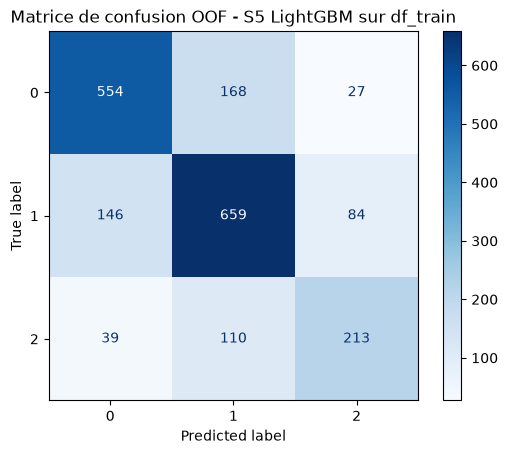

In [ ]:
# Évaluation détaillée du modèle retenu sur le jeu d'entraînement par validation croisée.
# Calcul des métriques de performance, des erreurs critiques et affichage
# de la matrice de confusion à partir des prédictions OOF.
# =======================================================================================
y_pred_oof_final = cross_val_predict(estimator=modele_final,
                                     X=X_train_final,
                                     y=y_train_final,
                                     cv=cv,
                                     method="predict",
                                     n_jobs=-1)

matrice_oof_finale = confusion_matrix(y_train_final,
                                      y_pred_oof_final,
                                      labels=[0, 1, 2])

nb_reels_classe_2_oof = matrice_oof_finale[2].sum()
nb_corrects_classe_2_oof = matrice_oof_finale[2, 2]
nb_erreurs_critiques_oof = matrice_oof_finale[2, 0]
nb_erreurs_non_critiques_oof = matrice_oof_finale[2, 1]

diagnostic_cv_modele_retenu = pd.DataFrame(
    [
        {
            "jeu": "Validation croisée OOF",
            "f1_macro": f1_score(
                y_train_final,
                y_pred_oof_final,
                average="macro",
            ),
            "recall_classe_2": (
                nb_corrects_classe_2_oof / nb_reels_classe_2_oof
            ),
            "taux_erreur_critique_2_vers_0": (
                nb_erreurs_critiques_oof / nb_reels_classe_2_oof
            ),
            "nb_erreurs_critiques_2_vers_0": nb_erreurs_critiques_oof,
            "nb_erreurs_non_critiques_2_vers_1": (
                nb_erreurs_non_critiques_oof
            ),
        }
    ]
)

display(diagnostic_cv_modele_retenu.round(4))

print("Rapport détaillé OOF sur df_train :")
print(classification_report(y_train_final,
                            y_pred_oof_final,
                            labels=[0, 1, 2],
                            zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_train_final,
                                        y_pred_oof_final,
                                        labels=[0, 1, 2],
                                        cmap="Blues")
plt.title("Matrice de confusion OOF - S5 LightGBM sur df_train")
plt.show()

,modèle,scénario,f1_macro_cv,f1_macro_test,taux_erreur_critique_cv,taux_erreur_critique_test
0,S5_LightGBM,S5,0.6955,0.7218,0.1078,0.0778


Rapport de classification sur le jeu de test :
              precision    recall  f1-score   support

           0       0.78      0.75      0.77       187
           1       0.71      0.80      0.75       223
           2       0.76      0.57      0.65        90

    accuracy                           0.74       500
   macro avg       0.75      0.71      0.72       500
weighted avg       0.74      0.74      0.74       500



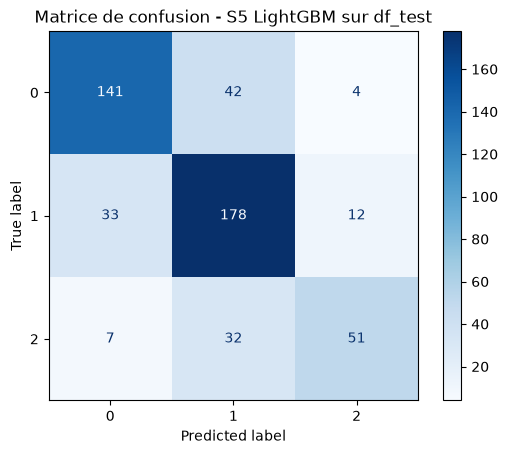

In [ ]:
# Évaluation finale sur le jeu de test non utilisé
# ================================================

y_pred_test = modele_final.predict(X_test_final)

metriques_test = {"f1_macro_test": f1_score(y_test_final, y_pred_test, average="macro"),
                  "taux_erreur_critique_test": taux_erreur_critique(y_test_final, y_pred_test)}

tableau_resultats_test = pd.DataFrame(
    [
        {
            "modèle": MODELE_RETENU,
            "scénario": f"S{num_scenario_final}",
            "f1_macro_cv": configuration_finale["f1_macro_cv"],
            "f1_macro_test": metriques_test["f1_macro_test"],
            "taux_erreur_critique_cv": (
                configuration_finale["taux_erreur_critique_cv"]
            ),
            "taux_erreur_critique_test": (
                metriques_test["taux_erreur_critique_test"]
            ),
        }
    ]
)

display(tableau_resultats_test.round(4))

print("Rapport de classification sur le jeu de test :")
print(classification_report(y_test_final,
                            y_pred_test,
                            labels=[0, 1, 2],
                            zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test_final,
                                        y_pred_test,
                                        labels=[0, 1, 2],
                                        cmap="Blues")
plt.title("Matrice de confusion - S5 LightGBM sur df_test")
plt.show()

In [ ]:
# Contrôle final du disparate impact sur le jeu de test
# =====================================================
donnees_sensibles_test = df_test.loc[
    X_test_final.index,
    ["age", "nationalite_hors_ue"],
].copy()

donnees_sensibles_test["tranche_age"] = pd.cut(donnees_sensibles_test["age"],
                                               bins=[18, 30, 40, 50, 60, 70],
                                               labels=["18-29", "30-39", "40-49", "50-59", "60+"],
                                               right=False)

outcome_favorable_test = pd.Series(np.isin(y_pred_test, [0, 1]).astype(int),
                                   index=X_test_final.index)

resultats_di_test = []

for nom_attribut, colonne_groupe, groupe_reference in [
    ("age", "tranche_age", "30-39"),
    ("nationalite_hors_ue", "nationalite_hors_ue", 0),
]:
    di_test = calculer_di(groupes=donnees_sensibles_test[colonne_groupe],
                          outcome_favorable=outcome_favorable_test,
                          groupe_reference=groupe_reference,
                          nom_taux="taux_outcome_favorable_predit")

    di_test = di_test.rename(columns={colonne_groupe: "groupe",
                                      "disparate_impact": "di_predit_test"})
    di_test["attribut"] = nom_attribut
    di_test["niveau_risque_di"] = np.select(
        [
            di_test["di_predit_test"] < 0.70,
            di_test["di_predit_test"] < 0.80,
        ],
        [
            "Disparité préoccupante",
            "Vigilance",
        ],
        default="DI satisfaisant",
    )

    resultats_di_test.append(di_test)

tableau_di_test = (
    pd.concat(resultats_di_test, ignore_index=True)
    .loc[
        :,
        [
            "attribut",
            "groupe",
            "effectif",
            "taux_outcome_favorable_predit",
            "di_predit_test",
            "niveau_risque_di",
        ],
    ]
    .sort_values(["attribut", "groupe"])
    .reset_index(drop=True)
)

display(tableau_di_test.round(3))

,attribut,groupe,effectif,taux_outcome_favorable_predit,di_predit_test,niveau_risque_di
0,age,18-29,130,0.923,0.945,DI satisfaisant
1,age,30-39,85,0.976,1.000,DI satisfaisant
2,age,40-49,105,0.971,0.995,DI satisfaisant
3,age,50-59,122,0.713,0.730,Vigilance
4,age,60+,36,0.556,0.569,Disparité préoccupante
5,nationalite_hors_ue,0,444,0.892,1.000,DI satisfaisant
6,nationalite_hors_ue,1,56,0.661,0.741,Vigilance


In [287]:
# Contrôle de qualité du modèle final sur le jeu de test.
SEUILS_QUALITE = {
    # Performance minimale attendue.
    "f1_macro_min": 0.68,

    # Erreur métier critique maximale tolérée.
    "taux_erreur_critique_max": 0.12,

    # En dessous de ce DI, une revue humaine est obligatoire.
    "di_min_bloquant": 0.70,
}

controle_performance = pd.DataFrame(
    [
        {
            "métrique": "F1 macro",
            "valeur_test": metriques_test["f1_macro_test"],
            "seuil": SEUILS_QUALITE["f1_macro_min"],
            "règle": ">=",
            "statut": (
                "OK"
                if metriques_test["f1_macro_test"]
                >= SEUILS_QUALITE["f1_macro_min"]
                else "ECHEC"
            ),
        },
        {
            "métrique": "Taux d'erreur critique 2 -> 0",
            "valeur_test": metriques_test["taux_erreur_critique_test"],
            "seuil": SEUILS_QUALITE["taux_erreur_critique_max"],
            "règle": "<=",
            "statut": (
                "OK"
                if metriques_test["taux_erreur_critique_test"]
                <= SEUILS_QUALITE["taux_erreur_critique_max"]
                else "ECHEC"
            ),
        },
    ]
)

controle_equite = (
    tableau_di_test
    .assign(
        métrique=lambda table: (
            "DI - "
            + table["attribut"].astype(str)
            + " / "
            + table["groupe"].astype(str)
        ),
        valeur_test=lambda table: table["di_predit_test"],
        seuil=SEUILS_QUALITE["di_min_bloquant"],
        règle=">=",
        statut=lambda table: np.where(
            table["di_predit_test"] >= SEUILS_QUALITE["di_min_bloquant"],
            "OK",
            "ECHEC - revue humaine requise",
        ),
    )
    [["métrique", "valeur_test", "seuil", "règle", "statut"]]
)

print("Contrôle des performances")
display(controle_performance.round(3))

print("Contrôle d'équité")
display(controle_equite.round(3))

Contrôle des performances


,métrique,valeur_test,seuil,règle,statut
0,F1 macro,0.722,0.68,>=,OK
1,Taux d'erreur critique 2 -> 0,0.078,0.12,<=,OK


Contrôle d'équité


,métrique,valeur_test,seuil,règle,statut
0,DI - age / 18-29,0.945,0.7,>=,OK
1,DI - age / 30-39,1.000,0.7,>=,OK
2,DI - age / 40-49,0.995,0.7,>=,OK
3,DI - age / 50-59,0.730,0.7,>=,OK
4,DI - age / 60+,0.569,0.7,>=,ECHEC - revue humaine requise
5,DI - nationalite_hors_ue / 0,1.000,0.7,>=,OK
6,DI - nationalite_hors_ue / 1,0.741,0.7,>=,OK


## 6 📝 Synthèse modélisation - Analyse des scénarios & arbitrages

- L’analyse des F1-scores macro montre que l’ensemble des modèles évalués obtient des performances nettement supérieures à celles d’une simple prédiction basée sur la classe majoritaire, ce qui confirme leur capacité à exploiter l’information présente dans les données.

- L'analyse des différents scénarios a mis en évidence les éléments suivants :
    - L'encodage de la synthèse d'entretien comme variable catégorielle donne de meilleurs résultats que sa vectorisation avec TF-IDF
    - L'encodage ordinal du niveau de diplôme n'améliore pas les métriques observées
    - Le texte et les variables sensibles `age` et `nationalite_hors_ue` apportent de l'information prédictive. Leur retrait dégrade les performances, mais leur utilisation implique un risque d'équité qui impose le contrôle des disparates impacts

- Le modèle **LightGBM** entraîné sur le scénario **S5** (Baseline avec toutes les variables, dont le texte de synthèse encodé en variable catégorielle) a été retenu après comparaison en validation croisée avec Random Forest sur le même scénario. Il a ensuite été entraîné sur l'ensemble du jeu d'entraînement, avec les hyperparamètres sélectionnés, puis évalué sur le jeu de test indépendant.

- Sur le jeu de test, le modèle obtient un F1-score macro de **0,7218**, supérieur au score observé en validation croisée (**0,6955**). Ce score confirme une généralisation satisfaisante et ne met pas en évidence de surapprentissage. Le taux d'erreur critique entre les classes $2 \rightarrow 0$ est également comparé au seuil défini avant l'évaluation finale.

- Pour l'industrialisation, nous adoptons une stratégie de seuils **hybride** :
    - un seuil absolu de F1-score macro fixé à $0{,}68$, afin de garantir un niveau minimal de qualité prédictive ;
    - un seuil absolu de taux d'erreur critique $2 \rightarrow 0$ fixé à $12\%$, car cette erreur peut conduire à sous-estimer les besoins d'accompagnement d'un usager ;
    - une tolérance relative initiale de $0{,}018$ est retenue pour le F1-score macro. Cette valeur est égale à deux fois l'écart-type observé en validation croisée stratifiée ($2 \times 0{,}0089 = 0{,}0178$). 
    - Le seuil relatif sera appliqué aux versions ultérieures par comparaison avec un jeu de référence figé. Cette tolérance devra être recalibré par bootstrap sur ce jeu de référence.

- Le contrôle d'équité met en évidence au moins un disparate impact inférieur au seuil bloquant de $0{,}70$. En particulier, les résultats doivent être examinés avec vigilance pour les groupes présentant une disparité préoccupante. Le modèle ne doit donc pas être utilisé pour prendre une décision entièrement automatisée.

- Le modèle peut être envisagé comme une **aide à la décision sous supervision humaine** : la prédiction doit être interprétée par un conseiller, en particulier pour les situations associées à un risque de retour à l'emploi de longue durée et pour les groupes identifiés comme sensibles dans l'analyse d'équité.

En conclusion, le modèle obtenu avec le scénario **S5 LightGBM**  est validé comme **composant d'aide à la décision**, mais pas comme outil de décision autonome. Son déploiement devra s'accompagner d'une supervision humaine, d'un suivi régulier des erreurs critiques et d'un contrôle périodique des indicateurs d'équité par âge et nationalité.

---
## 7. Interprétation pour la communication client (préparation soutenance)

**Compétences** : C8 (mesurer la performance et les impacts) + transversal communication

🎯 Rendre le modèle **lisible par un non-data scientist**. **Cette section est la base de ton pitch oral de soutenance** (15 min × jury de 2 pros). Elle ne couvre pas C8 stricto sensu (les sections 5, 6 et 9 le font) mais en restitue les résultats en langage métier.

💡 Feature importance, SHAP (optionnel), matrice de confusion commentée. Trois messages-clés maximum dans ton pitch oral, pas dix.

In [289]:
# 7.1 Importance globale des variables du modèle final LightGBM.

preprocessor_final = modele_final.named_steps["preprocessor"]
modele_lightgbm_final = modele_final.named_steps["model"]

noms_features_transformees = preprocessor_final.get_feature_names_out()

importance_features = (
    pd.DataFrame(
        {
            "feature_transformee": noms_features_transformees,
            "importance": modele_lightgbm_final.feature_importances_,
        }
    )
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

print("Variables transformées les plus importantes")
display(importance_features.head(10))

Variables transformées les plus importantes


,feature_transformee,importance
0,num__anciennete_poste_ans,4664
1,num__age,3975
2,cat__niveau_diplome_Bac,402
3,cat__est_allocataire_0.0,363
4,cat__niveau_diplome_Sans diplôme,355
5,cat__nationalite_hors_ue_0,335
6,cat__niveau_diplome_Bac+5,279
7,"cat__synthese_entretien_Profil autonome, reche...",244
8,cat__synthese_entretien_Cumul de difficultés. ...,220
9,cat__synthese_entretien_Candidat très dynamiqu...,217


In [290]:
# Agrégation des importances par variable d'origine.
def retrouver_feature_origine(nom_feature: str) -> str:
    """Regroupe les colonnes transformées sous leur variable d'origine."""
    nom_sans_prefixe = nom_feature.split("__", maxsplit=1)[-1]

    for feature in (
        numeric_features
        + categorical_features
        + ordinal_features
        + ([text_feature] if text_feature is not None else [])
    ):
        if nom_sans_prefixe == feature or nom_sans_prefixe.startswith(f"{feature}_"):
            return feature

    return nom_sans_prefixe


importance_features["feature_origine"] = (
    importance_features["feature_transformee"]
    .map(retrouver_feature_origine)
)

importance_par_feature = (
    importance_features
    .groupby("feature_origine", as_index=False)["importance"]
    .sum()
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

importance_par_feature["importance_relative_pct"] = (
    100
    * importance_par_feature["importance"]
    / importance_par_feature["importance"].sum()
)

print("Importance agrégée par variable d'origine")
display(importance_par_feature.round(2))

Importance agrégée par variable d'origine


,feature_origine,importance,importance_relative_pct
0,anciennete_poste_ans,4664,25.91
1,age,3975,22.08
2,code_rome_vise,3488,19.38
3,departement,1910,10.61
4,synthese_entretien,1795,9.97
5,niveau_diplome,1251,6.95
6,est_allocataire,558,3.10
7,nationalite_hors_ue,359,1.99


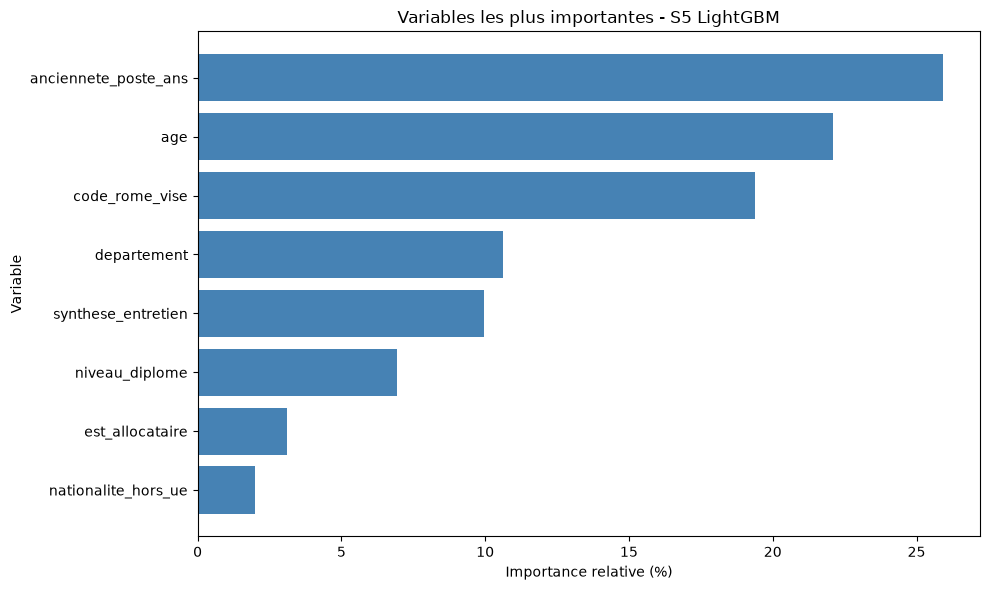

In [293]:
top_features = importance_par_feature.head(15).sort_values("importance")

plt.figure(figsize=(10, 6))
plt.barh(
    top_features["feature_origine"],
    top_features["importance_relative_pct"],
    color="steelblue",
)
plt.xlabel("Importance relative (%)")
plt.ylabel("Variable")
plt.title("Variables les plus importantes - S5 LightGBM")
plt.tight_layout()
plt.show()

### 7.2 Analyse des erreurs et stratégies de fallback

🎯 Identifier où le modèle échoue, et **concevoir le filet de sécurité** : que se passe-t-il quand le modèle a tort, ou qu'il ne sait pas ?

💡 Trois leviers de conception à documenter explicitement (la **surveillance** de ces seuils se traite en §9.4, pas ici) :

| Levier | Question à trancher | Exemple concret |
|---|---|---|
| **Rejection threshold** | À quel niveau de confiance je préfère m'abstenir plutôt que prédire ? | *[ex: si proba ∈ [0.4, 0.6], on n'émet pas de prédiction]* |
| **Abstention contrôlée** | Que renvoie l'API quand le modèle s'abstient ? | *[ex: HTTP 422 + payload « confiance insuffisante » + flag HITL]* |
| **Escalade humaine (HITL)** | Qui prend la main, sous quel délai, avec quelle interface ? | *[ex: file Slack #fastia-hitl, SLA 4h ouvrées, audit a posteriori]* |

⚠️ Sans ces 3 éléments, ton modèle n'a pas de plan de fallback — il **n'est pas déployable en prod sur un usage à enjeu**. C'est un attendu C8 N3 (M6) et C7 N3 (M8). Le code ci-dessous analyse les erreurs résiduelles pour **informer** ces 3 choix (où placer le seuil, quels profils escalader).

In [132]:
# 7.2 Analyse des erreurs et profils à escalader
# - Matrice de confusion détaillée par profil (variables sensibles incluses)
# - Distribution des probabilités prédites sur les erreurs : où placer le seuil de rejet ?
# - Caractérisation des profils faux positifs / faux négatifs : escalade humaine prioritaire ?

### 7.3 Message au client (langage métier)

*[2-3 paragraphes lisibles par un décideur non technique. Trois messages-clés à retenir.]*

### 7.4 📝 Synthèse interprétation

*[Variables-clés, profils mal prédits, vigilance opérationnelle.]*

---
## 8. Industrialisation

**Compétences** : C6 (implémenter le modèle), C7 (architecture cible)

🎯 Transformer le modèle en **service exploitable** : API, UI, conteneurs, tracking d'expériences.

> ⚠️ **Cette section ne contient PAS le code de l'API/UI.** Le code vit dans le **repo Git** associé.  
> Dans le notebook, on met uniquement :
> 1. **Description architecturale** (texte)
> 2. **1 schéma** d'architecture (Mermaid, draw.io export, ou image)
> 3. **Lien vers le repo Git** + dossiers concernés
> 4. **Captures d'écran clés** (UI, dashboard, OpenAPI Swagger, workflow CI/CD vert)
> 5. **Justifications des choix techniques** (pourquoi FastAPI plutôt que Flask, pourquoi MLflow plutôt que `experiments.md`, etc.)

⚠️ Attendus certif (présents dans le repo, **référencés** dans cette section du notebook) :  
- API FastAPI avec routes `/predict`, `/train`, `/health`  
- Validation Pydantic des entrées  
- Logging structuré (Loguru)  
- Tests pytest  
- Conteneurisation Docker  
- CI/CD GitHub Actions  
- Tracking MLflow

### 8.1 Persistance du modèle

*[Quel modèle est servi (`pipeline.joblib` versionné), quelle stratégie de persistance, quelle traçabilité (MLflow run id ou alternative `experiments.md`).]*

### 8.2 API de service

**Repo associé** : `<lien GitHub>` — dossier `api/`

| Route | Méthode | Rôle | Validation |
|---|---|---|---|
| `/health` | GET | santé du service | — |
| `/predict` | POST | prédiction unitaire | Pydantic |
| `/train` | POST | (option) déclenche un réentraînement | Pydantic + auth |

*[Inclure ici 1 capture Swagger ou un schéma de l'API.]*

### 8.3 Interface utilisateur

*[Streamlit / Gradio / autre. Capture dans `docs/`.]*

### 8.4 Schéma d'architecture

*[1 schéma simple : sources données → préprocessing → modèle → API → UI → monitoring.  
Tu peux utiliser un bloc Mermaid (rendu natif sur GitHub et Jupyter récents) :]*

```mermaid
graph LR
  D[(Données)] --> P[Préprocessing] --> M[Modèle .joblib]
  M --> A[FastAPI]
  A --> U[UI Streamlit]
  A --> L[(Logs)]
  L --> Mo[Monitoring]
```

### 8.5 Conteneurisation & CI/CD

*[Dockerfile, docker-compose.yml, workflow GitHub Actions (build → test → push). Captures d'écran d'un run CI vert. Liens vers les fichiers du repo.]*

### 8.6 📝 Synthèse industrialisation

*[Pile retenue, choix d'architecture, points encore ouverts.]*

---
## 9. Suivi en production & amélioration continue

**Compétences** : C8 (mesurer performance), C9 (amélioration continue)

🎯 Anticiper la dérive et la maintenance du modèle après mise en prod.

💡 Drift = data drift (entrées qui changent) vs concept drift (la cible change de comportement).  
⚠️ Pas de monitoring = pas de prod. Même un dashboard simple Streamlit suffit pour démarrer.

### 9.1 Métriques à surveiller

| Type | Métrique | Seuil d'alerte | Source |
|---|---|---|---|
| Modèle | F1 hebdo | < baseline - 0.05 | logs API |
| Données | PSI variables clés | > 0.2 | batch journalier |
| Système | latence p95 | > 500 ms | Prometheus |

### 9.2 Boucle de rétroaction

*[Comment les retours utilisateurs / annotations correctives reviennent dans les données d'entraînement ?]*

### 9.3 Plan de réentraînement

*[Trigger (calendaire ? performance ? volume nouvelles données ?), automatisation, validation avant mise en prod.]*

### 9.4 Robustesse en exploitation

🎯 Surveiller les **conditions de défaillance** une fois en prod, en complément des stratégies de fallback définies en §7.2 (côté conception).

💡 La conception du fallback (où placer le seuil, qui escalader) vit en §7.2. Ici on instrumente la **mesure** et le **déclenchement** :

| Axe | Métrique opérationnelle | Action automatique |
|---|---|---|
| **OOD (Out-Of-Distribution)** | Distance Mahalanobis ou score d'isolation sur les entrées | Logger les inputs hors-distribution, déclencher abstention ou escalade humaine (cf §7.2) |
| **Drift du seuil de rejet** | Taux d'abstention / part de prédictions sous seuil de confiance | Réviser le rejection threshold si dérive > 20 % sur 4 semaines glissantes |
| **Calibration** | Brier score, courbe de calibration mensuelle | Recalibrer (Platt, isotonic) sans réentraîner le modèle complet si seule la calibration dérive |

⚠️ La chaîne conception → exploitation doit rester explicite. §7.2 définit le filet de sécurité, §9.4 le surveille. Casser cette chaîne (fallback conçu mais jamais mesuré) = attendu C8 N3 non atteint.

### 9.5 📝 Synthèse amélioration continue

*[Cadence de surveillance, déclencheurs de réentraînement, plan de remédiation en cas de dérive.]*

---
## 📎 Annexes

### A. Glossaire métier & technique

### B. Sources & bibliographie

- *[Datasets, articles, documentation technique consultés]*

### C. Décisions techniques détaillées

*[Justifications longues qu'on ne met pas dans le corps du notebook pour le garder lisible.]*

### D. Journal de bord

**Pendant la formation**, le journal de bord est tenu **séparément** dans `journal-de-bord.ipynb` (plus pratique pour le rythme journalier).

⚠️ **Pour la certification**, les deux fichiers doivent être **fusionnés en un seul notebook** (cf. fiche descriptive Atlas IA — un cahier électronique unique).

#### Méthode 1 — Script de fusion (recommandée, ~30 secondes)

Un script est fourni à la racine du repo formation : `scripts/merge_for_certif.py`.

```bash
python scripts/merge_for_certif.py mon_notebook.ipynb journal-de-bord.ipynb rendu_certif.ipynb
```

Le script localise automatiquement le titre « D. Journal de bord » dans le notebook principal et y insère les cellules du journal dans l'ordre. Il produit un nouveau fichier sans modifier les sources.

#### Méthode 2 — Fusion manuelle dans JupyterLab (~5 min)

1. Ouvrir les **deux notebooks** côte à côte dans JupyterLab (drag-and-drop dans deux colonnes).
2. Dans le journal : cliquer sur la première cellule « Jour 1 », puis **Maj-clic** sur la dernière pour tout sélectionner sauf l'intro.
3. **Edit > Copy Cells** (`Ctrl/Cmd + Shift + C`).
4. Dans le notebook principal : cliquer sous le titre « D. Journal de bord ».
5. **Edit > Paste Cells Below** (`Ctrl/Cmd + Shift + V`).
6. Vérifier l'ordre chronologique.
7. **Kernel > Restart & Run All** : aucune cellule ne doit casser.
8. Sauvegarder sous un **nouveau nom** (ex : `<prenom>_certif_v1.ipynb`) — ne pas écraser les sources.

#### Vérification finale (les deux méthodes)

- [ ] Le notebook fusionné s'exécute de bout en bout sans erreur.
- [ ] Toutes les images du journal s'affichent (sinon : passer en chemins absolus ou inliner).
- [ ] Aucune référence à des fichiers externes hors du repo (ou alors les inclure dans le ZIP de rendu).
- [ ] Une seule version finale, datée, dans le ZIP envoyé au jury.

⚠️ **Tester la fusion 2-3 jours avant le rendu**, pas le jour J.

#### Export PDF (optionnel, pour la soutenance)

```bash
jupyter nbconvert --to pdf rendu_certif.ipynb
```